In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime

In [2]:
def get_n_qtr_fwd_bwd(cq,nq,forward=True,leading_zeros=True):
    cy = int(cq.split("FY")[1])
    cqn = int(cq[1])
    if leading_zeros:
        l = [
            f"Q{i % 4 + 1}FY{(cy + (i // 4)) % 100:02d}"  # Format year to have leading zeros
            for i in range(cqn, cqn + nq)
        ] if forward else [
            f"Q{i % 4 + 1}FY{(cy + (i // 4)) % 100:02d}"  # Format year to have leading zeros
            for i in range(cqn - nq, cqn - 1)
        ]
    else:
        l = [f"Q{i % 4 + 1}FY{cy + (i // 4)}" for i in range(cqn, cqn+nq)] if forward==True else [f"Q{i % 4 + 1}FY{cy + (i // 4)}" for i in range(cqn-nq,cqn-1)]  
    return l
def get_nth_qtr_fwd_bwd(cq, nq, forward=True,leading_zeros=True):
    cy = int(cq.split("FY")[1])
    cqn = int(cq[1])
    if not forward:
        nq = -nq
    new_qn = (cqn - 1 + nq) % 4 + 1
    new_cy = cy + (cqn - 1 + nq) // 4
    if leading_zeros:
        new_cy = f"{new_cy}" if new_cy >=10 else f"0{new_cy}"
    else:
        new_cy = f"{new_cy}"
    return f"Q{new_qn}FY{new_cy}"

def convert_qtr_to_date(qtr):
    y = int(qtr.split("FY")[1])
    q = int(qtr.split("FY")[0][-1])
    quarter_end_dates = {
        "Q1": "30-06-",
        "Q2": "30-09-",
        "Q3": "31-12-",
        "Q4": "31-03-"
    }
    y = y if q==4 else y-1
    fiscal_year = 2000 + int(y)
    end_date = quarter_end_dates.get(f'Q{q}')
    if end_date:
        return end_date + str(fiscal_year)  # Concatenate the end date with the full year
    else:
        raise ValueError("Invalid quarter format")

def get_financial_quarter(date_str):
    date = datetime.strptime(date_str, "%Y-%m-%d")
    month = date.month
    year = date.year
    quarter = ((month - 4) % 12) // 3 + 1
    fin_year = year + 1 if month >= 4 else year
    return f"Q{quarter}FY{str(fin_year)[-2:]}"


In [3]:
df_load = pd.read_excel(r"D:\FY25-26\Quant Fund\data\Time_Series_Master_wo_Index_Last20Yrs1.xlsx")

In [49]:
df = df_load.copy()

In [50]:
df.head()

,Ticker,Quarter,DE,ROCE,ROE,ROA,PB,PE,Ast_TO,NI_Growth,...,Volatility,Momentum,SMR,TMR,Beta,Zscore,Price,Returns,Rank,Target
0,reliance,Q4FY05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,10.147323,0.70,5.388004,1.501305,0.545504,-0.416962,31.10,0.176527,180.0,0.0
1,reliance,Q1FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,17.226768,5.49,20.361842,49.591169,0.997255,-0.422182,36.59,0.235037,225.0,NaN
2,reliance,Q2FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,21.182862,8.60,45.305466,53.134531,0.818094,-0.316829,45.19,0.120602,165.0,0.0
3,reliance,Q3FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,18.261520,5.45,38.398470,66.578947,0.898060,-0.270389,50.64,0.771722,22.0,1.0
4,reliance,Q4FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,97.900865,39.08,98.539500,188.488746,-0.778503,0.283288,89.72,0.332590,18.0,1.0


In [51]:
df_ticker_analysis = pd.DataFrame(df['Ticker'].value_counts())

In [52]:
df_ticker_analysis.reset_index(inplace=True)

In [53]:
df_ticker_analysis.tail()

,Ticker,count
937,aadharhf,3
938,tbotek,3
939,awfis,3
940,godigit,3
941,bhartihe,3


In [54]:
df_ticker_analysis.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 942 entries, 0 to 941
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Ticker  942 non-null    object
 1   count   942 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 14.8+ KB


In [55]:
df_ticker_analysis.describe()

,count
count,942.000000
mean,57.083864
std,28.555563
min,3.000000
25%,29.000000
50%,80.000000
75%,80.000000
max,80.000000


#### Data Splits - figuring out different combinations

In [56]:
# all_qtrs_series = pd.Series(df['Quarter'].unique())
# all_qtrs_series = pd.to_datetime(all_qtrs_series.apply(convert_qtr_to_date),dayfirst=True)

In [57]:
# date_qtr_mapping = pd.DataFrame({'Date':all_qtrs_series,'Quarter':pd.Series(df['Quarter'].unique())})

In [58]:
# from sklearn.model_selection import train_test_split

In [59]:
# # all_qtrs = list(df['Quarter'].unique())
# no_of_diff_splits = 5
# test_size = 0.25
# list_of_dates_split_df = []
# for i in range(no_of_diff_splits):
#     train_dates, test_dates = train_test_split(all_qtrs_series, test_size=test_size, shuffle=True)
#     df_test_dates1 = pd.DataFrame({'Quarter':test_dates,'Set':['Test']*len(test_dates)})
#     df_train_dates1 = pd.DataFrame({'Quarter':train_dates,'Set':['Train']*len(train_dates)})
#     df_dates_split = pd.concat([df_test_dates1,df_train_dates1],axis=0)
#     list_of_dates_split_df.append(df_dates_split)


In [60]:
# with pd.ExcelWriter(rf'D:\FY25-26\Quant Fund\data\data_splits_07_06_2025_test_size_{test_size*100}%.xlsx', engine='xlsxwriter') as writer:
#     for i,df_dates_split1 in enumerate(list_of_dates_split_df):
#         df_dates_split1.to_excel(writer,sheet_name=f'Split{i+0}',index=False)

In [61]:
df.columns

Index(['Ticker', 'Quarter', 'DE', 'ROCE', 'ROE', 'ROA', 'PB', 'PE', 'Ast_TO',
       'NI_Growth', 'Volume_Growth', 'Mkt_Cap_Growth', 'EBITDA_Growth',
       '200_MVA_Growth', '50D_MVA_Growth', 'Revenue_Growth', 'Dividend_Growth',
       'Abn_Gain_Loss_Growth', 'Dividend_Flag', 'Abn_Gain_Loss_Flag',
       'Mkt_Cap', 'CFO', 'EV_EBITDA', 'ICR', 'Earnings_Growth', 'EPS', 'FCF',
       'PS', 'PEG', 'Std', 'Alpha', 'Volatility', 'Momentum', 'SMR', 'TMR',
       'Beta', 'Zscore', 'Price', 'Returns', 'Rank', 'Target'],
      dtype='object')

### Fund - 1

#### Random Splits

In [897]:
df['EP'] = 1/df['PE']
df['BP'] = 1/df['PB']
df['SP'] = 1/df['PS']

In [898]:
params_f1 = ['SMR','TMR','Volatility','Std','Momentum','Beta','Alpha','EP','BP','SP','Dividend_Flag','ROE','DE','EPS','Zscore']

In [104]:
df1 = df[['Ticker','Quarter']+params_f1+['Target']]

##### Missing value Analysis

(array([10.,  4.,  1.,  0.,  0.,  0.,  0.,  0.,  2.,  1.]),
 array([ 0.        ,  8.30286575, 16.6057315 , 24.90859725, 33.211463  ,
        41.51432875, 49.8171945 , 58.12006025, 66.422926  , 74.72579175,
        83.0286575 ]),
 <BarContainer object of 10 artists>)

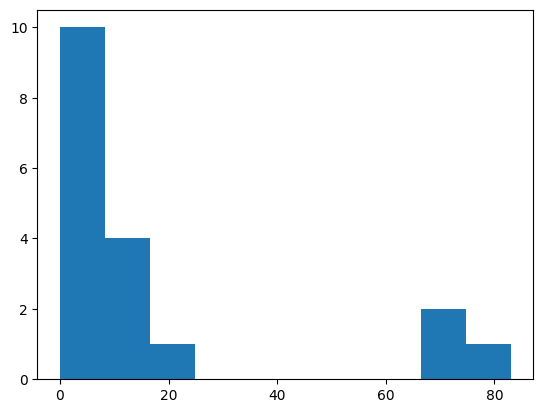

In [105]:
df1_missing = pd.DataFrame(df1.isna().sum()).reset_index(drop=False).rename(columns={'index':'col',0:'missing'})
df1_missing['missing_perc'] = df1_missing['missing'].divide(df1.shape[0])*100
plt.hist(df1_missing['missing_perc'])

In [106]:
df1_missing.columns

Index(['col', 'missing', 'missing_perc'], dtype='object')

In [107]:
df1_missing.shape

(18, 3)

In [108]:
df1_missing[df1_missing['missing_perc']>80].shape

(1, 3)

In [109]:
df1_missing[df1_missing['missing_perc']>80]['col'].to_list()

['ROE']

In [110]:
missing_cols_drop = df1_missing[df1_missing['missing_perc']>80]['col'].to_list()
df1.drop(columns=missing_cols_drop,inplace=True)
df1.reset_index(drop=True,inplace=True)

C:\Users\35098\AppData\Local\Temp\ipykernel_14796\3076753156.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1.drop(columns=missing_cols_drop,inplace=True)


In [111]:
df1.head()

,Ticker,Quarter,SMR,TMR,Volatility,Std,Momentum,Beta,Alpha,EP,BP,SP,Dividend_Flag,DE,EPS,Zscore,Target
0,reliance,Q4FY05,5.388004,1.501305,10.147323,1.278443,0.70,0.545504,0.004054,NaN,NaN,NaN,1,NaN,NaN,-0.416962,0.0
1,reliance,Q1FY06,20.361842,49.591169,17.226768,2.170369,5.49,0.997255,0.130998,NaN,NaN,NaN,1,NaN,NaN,-0.422182,NaN
2,reliance,Q2FY06,45.305466,53.134531,21.182862,2.668790,8.60,0.818094,0.023372,NaN,NaN,NaN,1,NaN,NaN,-0.316829,0.0
3,reliance,Q3FY06,38.398470,66.578947,18.261520,2.300735,5.45,0.898060,0.061364,NaN,NaN,NaN,0,NaN,NaN,-0.270389,1.0
4,reliance,Q4FY06,98.539500,188.488746,97.900865,12.334350,39.08,-0.778503,0.802280,NaN,NaN,NaN,1,NaN,NaN,0.283288,1.0


In [116]:
df1['Quarter_Date'] = pd.to_datetime(df1['Quarter'].apply(convert_qtr_to_date),dayfirst=True)

C:\Users\35098\AppData\Local\Temp\ipykernel_14796\340028024.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1['Quarter_Date'] = pd.to_datetime(df1['Quarter'].apply(convert_qtr_to_date),dayfirst=True)


In [119]:
all_dates = list(df1['Quarter_Date'].unique())

In [120]:
all_dates = pd.Series(all_dates)

In [121]:
all_dates.is_monotonic_increasing

True

In [125]:
all_dates[0:7]

0   2005-03-31
1   2005-06-30
2   2005-09-30
3   2005-12-31
4   2006-03-31
5   2006-06-30
6   2006-09-30
dtype: datetime64[ns]

In [128]:
int(np.round(len(all_dates)*test_size))

24

In [130]:
train_dates = all_dates[:int(np.round(len(all_dates)*test_size))]
test_dates = all_dates[int(np.round(len(all_dates)*test_size)):]

In [131]:
set(train_dates).intersection(test_dates)

set()

In [134]:
df1['Set'] = np.where(df1['Quarter_Date'].isin(train_dates),"Train",'Test')

C:\Users\35098\AppData\Local\Temp\ipykernel_14796\2087473753.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1['Set'] = np.where(df1['Quarter_Date'].isin(train_dates),"Train",'Test')


In [27]:
#### Considering 1st Random split
test_size = 0.3
print(test_size)
split = 'Split1'
df_splits = pd.read_excel(rf'D:\FY25-26\Quant Fund\data\data_splits_07_06_2025_test_size_{test_size*100}%.xlsx',sheet_name=split)

0.3


In [28]:
df_splits.head()

,Quarter,Set
0,2007-06-30,Test
1,2016-03-31,Test
2,2008-12-31,Test
3,2019-09-30,Test
4,2013-03-31,Test


In [29]:
df_splits['Quarter'] = df_splits['Quarter'].astype(str)

In [30]:
df_splits.loc[:,'Quarter'] = df_splits['Quarter'].apply(get_financial_quarter)

In [31]:
df_fin_11 = df1.merge(df_splits,on='Quarter',how='left')
df_fin_11['Set'].isna().sum()

np.int64(0)

In [32]:
# df.fillna({'Target':0},inplace=True)

In [136]:
# list(df1.columns)

In [137]:
# iv_cols = list(df_fin_11.columns)
# misc_cols = ['Ticker','Quarter','Target','Set']
iv_cols = list(df1.columns)
misc_cols = ['Ticker','Quarter','Quarter_Date','Target','Set']
for col in misc_cols:
    iv_cols.remove(col)

In [138]:
iv_cols

['SMR',
 'TMR',
 'Volatility',
 'Std',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore']

In [140]:
df_fin_11 = df1.copy()  # for time based split

In [141]:
df_fin_11['Quarter'] = df_fin_11['Quarter'].apply(convert_qtr_to_date)
df_fin_11['Quarter'] = pd.to_datetime(df_fin_11['Quarter'],dayfirst=True)

In [142]:
df_train = df_fin_11[df_fin_11['Set']=='Train']
df_test = df_fin_11[df_fin_11['Set']=='Test']

##### imputation

In [143]:
df_train.columns

Index(['Ticker', 'Quarter', 'SMR', 'TMR', 'Volatility', 'Std', 'Momentum',
       'Beta', 'Alpha', 'EP', 'BP', 'SP', 'Dividend_Flag', 'DE', 'EPS',
       'Zscore', 'Target', 'Quarter_Date', 'Set'],
      dtype='object')

In [144]:
iv_cols

['SMR',
 'TMR',
 'Volatility',
 'Std',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore']

In [145]:
df_train.loc[:,'Quarter'] = pd.to_datetime(df_train['Quarter'],dayfirst=True)
df_test.loc[:,'Quarter'] = pd.to_datetime(df_test['Quarter'],dayfirst=True)

In [146]:
df_train = df_train.set_index(['Quarter'])
df_test = df_test.set_index(['Quarter'])

In [147]:
iv_cols

['SMR',
 'TMR',
 'Volatility',
 'Std',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore']

In [148]:
for col in iv_cols:
    df_train.loc[:,col] = df_train[col].astype(float)
    df_test.loc[:,col] = df_test[col].astype(float)
    df_train.loc[:,col] = df_train.groupby('Ticker')[col].transform(lambda group: group.interpolate(method='time',limit_direction='forward'))
    df_test.loc[:,col] = df_test.groupby('Ticker')[col].transform(lambda group: group.interpolate(method='time',limit_direction='forward'))

In [149]:
df_train.isna().sum()

Ticker              0
SMR               269
TMR               514
Volatility         28
Std                28
Momentum          150
Beta               31
Alpha              31
EP               3844
BP               3378
SP               3452
Dividend_Flag       0
DE               3760
EPS              3589
Zscore            186
Target           8211
Quarter_Date        0
Set                 0
dtype: int64

In [150]:
df_train.reset_index(inplace=True)
df_test.reset_index(inplace=True)

In [151]:
for col in iv_cols:
    df_train.loc[:,col] = df_train.groupby('Quarter')[col].transform(lambda group: group.fillna(group.median()))
    df_test.loc[:,col] = df_test.groupby('Quarter')[col].transform(lambda group: group.fillna(group.median()))

In [152]:
df_test.isna().sum()

Quarter              0
Ticker               0
SMR                  0
TMR                  0
Volatility           0
Std                  0
Momentum             0
Beta                 0
Alpha                0
EP                   0
BP                   0
SP                   0
Dividend_Flag        0
DE                   0
EPS                  0
Zscore               0
Target           30358
Quarter_Date         0
Set                  0
dtype: int64

In [153]:
df_train.fillna({'Target':0},inplace=True)
df_test.fillna({'Target':0},inplace=True)

In [154]:
df_train['Ticker'].nunique()

594

In [155]:
df_train['Year'] = df_train['Quarter'].dt.year
df_train['Quarter_number'] = df_train['Quarter'].dt.quarter

df_test['Year'] = df_test['Quarter'].dt.year
df_test['Quarter_number'] = df_test['Quarter'].dt.quarter

##### Multi-collinearity check

In [156]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [157]:
iv_cols

['SMR',
 'TMR',
 'Volatility',
 'Std',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore']

In [158]:
iv_cols = iv_cols + ['Year','Quarter_number']

In [159]:
vif_data = pd.DataFrame()
vif_data["feature"] = iv_cols

In [160]:
df_train[iv_cols].isin([np.inf,-np.inf]).sum()

SMR               0
TMR               0
Volatility        0
Std               0
Momentum          0
Beta              0
Alpha             0
EP                0
BP                0
SP                0
Dividend_Flag     0
DE                0
EPS               0
Zscore            0
Year              0
Quarter_number    0
dtype: int64

In [161]:
df_train.replace([np.inf,-np.inf],0,inplace=True)

In [162]:
for col in iv_cols:
    df_train.loc[:,col] = df_train[col].astype(float)

In [163]:
vif_data["VIF"] = [variance_inflation_factor(df_train[iv_cols].values, i) for i in range(len(iv_cols))]

d:\Quant Fund\qf_33\lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)
d:\Quant Fund\qf_33\lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


In [164]:
vif_data.head()

,feature,VIF
0,SMR,2.213642
1,TMR,1.731591
2,Volatility,inf
3,Std,inf
4,Momentum,1.067825


In [165]:
# vif_data['feature']

In [166]:
vif_data[vif_data['VIF']>=5]['feature'].to_list()

['Volatility', 'Std', 'Year', 'Quarter_number']

In [167]:
vif_cols = vif_data[vif_data['VIF']<5]['feature'].to_list()
vif_cols

['SMR',
 'TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore']

In [168]:
import seaborn as sns

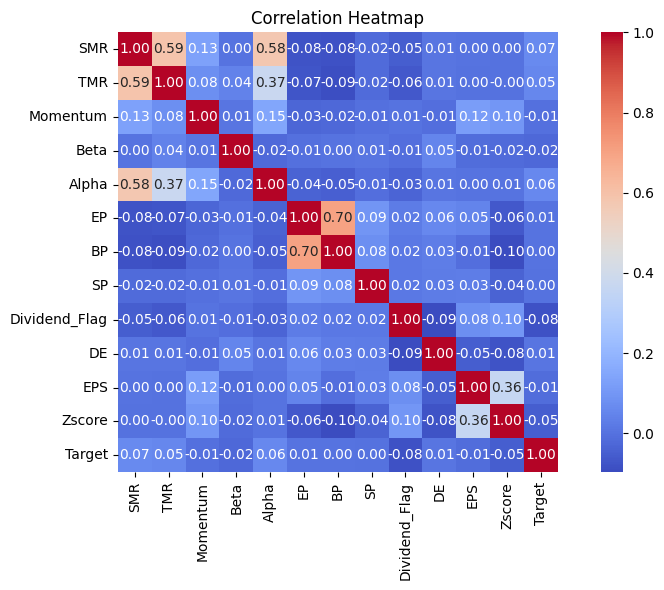

In [169]:
# ...existing code...

import matplotlib.pyplot as plt
import seaborn as sns

corr = df_train[vif_cols + ['Target']].corr()
plt.figure(figsize=(9, 6))
ax = sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", square=True)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=300)
plt.show()
# ...existing code...

In [170]:
for col in ['BP']:
    vif_cols.remove(col)

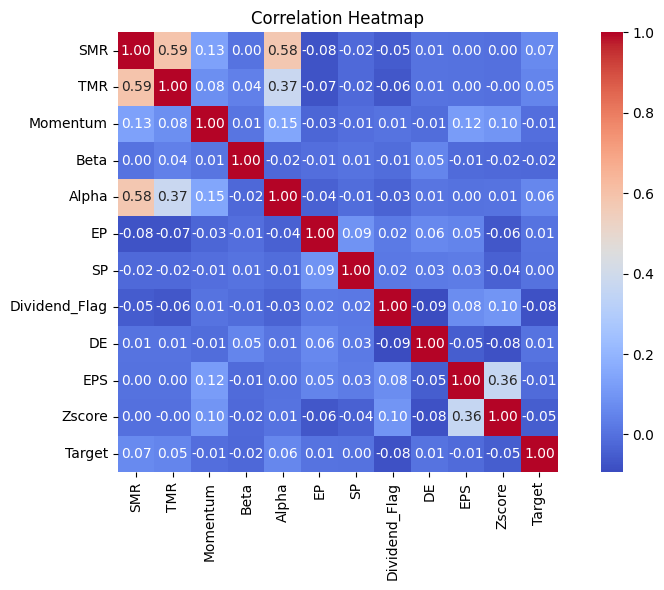

In [171]:
corr = df_train[vif_cols + ['Target']].corr()
plt.figure(figsize=(9, 6))
ax = sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", square=True)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=300)
plt.show()
# ...existing code...

In [172]:
sign_cols = ['Ticker','Quarter']+vif_cols+['Target']

In [173]:
int(test_size*100)

30

In [176]:
# df_train[sign_cols]

In [178]:
# df_train[sign_cols].to_excel(rf"D:\FY25-26\Quant Fund\Fund1\data\train_data_after_multicollinearity_correlation_{int(test_size*100)}_test_size_time_based_split.xlsx",index=False)
# df_test[sign_cols].to_excel(rf"D:\FY25-26\Quant Fund\Fund1\data\test_data_after_multicollinearity_correlation_{int(test_size*100)}_test_size_time_based_split.xlsx",index=False)

In [97]:
df_train1 = df_train[sign_cols]
df_test1 = df_test[sign_cols]
df_train1['Set'] = 'Train'
df_test1['Set'] = 'Test'

C:\Users\35098\AppData\Local\Temp\ipykernel_14796\3240530298.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train1['Set'] = 'Train'
C:\Users\35098\AppData\Local\Temp\ipykernel_14796\3240530298.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test1['Set'] = 'Test'


In [99]:
df_fund1 = pd.concat([df_train1,df_test1],axis=0)

In [100]:
# df_fund1.to_excel(r"D:\FY25-26\Quant Fund\Fund1\data\model_data_fund1_with_sign_features.xlsx",index=False)

#### Time Based Split

In [159]:
test_size = (3/20)

In [160]:
df = df_load.copy()

In [161]:
df.head()

,Ticker,Quarter,DE,ROCE,ROE,ROA,PB,PE,Ast_TO,NI_Growth,...,Volatility,Momentum,SMR,TMR,Beta,Zscore,Price,Returns,Rank,Target
0,reliance,Q4FY05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,10.147323,0.70,5.388004,1.501305,0.545504,-0.416962,31.10,0.176527,180.0,0.0
1,reliance,Q1FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,17.226768,5.49,20.361842,49.591169,0.997255,-0.422182,36.59,0.235037,225.0,NaN
2,reliance,Q2FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,21.182862,8.60,45.305466,53.134531,0.818094,-0.316829,45.19,0.120602,165.0,0.0
3,reliance,Q3FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,18.261520,5.45,38.398470,66.578947,0.898060,-0.270389,50.64,0.771722,22.0,1.0
4,reliance,Q4FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,97.900865,39.08,98.539500,188.488746,-0.778503,0.283288,89.72,0.332590,18.0,1.0


In [162]:
df['EP'] = 1/df['PE']
df['BP'] = 1/df['PB']
df['SP'] = 1/df['PS']

In [163]:
df.columns

Index(['Ticker', 'Quarter', 'DE', 'ROCE', 'ROE', 'ROA', 'PB', 'PE', 'Ast_TO',
       'NI_Growth', 'Volume_Growth', 'Mkt_Cap_Growth', 'EBITDA_Growth',
       '200_MVA_Growth', '50D_MVA_Growth', 'Revenue_Growth', 'Dividend_Growth',
       'Abn_Gain_Loss_Growth', 'Dividend_Flag', 'Abn_Gain_Loss_Flag',
       'Mkt_Cap', 'CFO', 'EV_EBITDA', 'ICR', 'Earnings_Growth', 'EPS', 'FCF',
       'PS', 'PEG', 'Std', 'Alpha', 'Volatility', 'Momentum', 'SMR', 'TMR',
       'Beta', 'Zscore', 'Price', 'Returns', 'Rank', 'Target', 'EP', 'BP',
       'SP'],
      dtype='object')

In [164]:
df['Abn_Gain_Loss_Flag'].value_counts()

Abn_Gain_Loss_Flag
-1.0    3604
 1.0    2665
Name: count, dtype: int64

In [165]:
df['Abn_Gain_Loss_Flag'].fillna(0,inplace=True)

C:\Users\35098\AppData\Local\Temp\ipykernel_12560\735944254.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Abn_Gain_Loss_Flag'].fillna(0,inplace=True)


In [166]:
df['Earnings_Growth'].describe()

count    3273.000000
mean             inf
std              NaN
min      -215.588542
25%        -0.223712
50%         0.025641
75%         0.199422
max              inf
Name: Earnings_Growth, dtype: float64

In [167]:
df['Earnings_Growth'].replace([np.inf,-np.inf,np.nan],0,inplace=True)

C:\Users\35098\AppData\Local\Temp\ipykernel_12560\2245785938.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Earnings_Growth'].replace([np.inf,-np.inf,np.nan],0,inplace=True)


In [168]:
df.shape

(53773, 44)

In [169]:
# df['EBITDA_Growth']
df[df['Ticker']=='reliance']['Revenue_Growth'].isna().sum()

np.int64(60)

In [170]:
df_check = df.set_index(keys=['Ticker']).groupby(by=['Ticker']).ffill()
df_check.reset_index(inplace=True)

In [171]:
df_check.head()

,Ticker,Quarter,DE,ROCE,ROE,ROA,PB,PE,Ast_TO,NI_Growth,...,TMR,Beta,Zscore,Price,Returns,Rank,Target,EP,BP,SP
0,reliance,Q4FY05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.501305,0.545504,-0.416962,31.10,0.176527,180.0,0.0,NaN,NaN,NaN
1,reliance,Q1FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,49.591169,0.997255,-0.422182,36.59,0.235037,225.0,0.0,NaN,NaN,NaN
2,reliance,Q2FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,53.134531,0.818094,-0.316829,45.19,0.120602,165.0,0.0,NaN,NaN,NaN
3,reliance,Q3FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,66.578947,0.898060,-0.270389,50.64,0.771722,22.0,1.0,NaN,NaN,NaN
4,reliance,Q4FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,188.488746,-0.778503,0.283288,89.72,0.332590,18.0,1.0,NaN,NaN,NaN


In [172]:
# df_check[df_check['Ticker']=='reliance'][~df_check[df_check['Ticker']=='reliance']['Revenue_Growth'].isna()]['Revenue_Growth']

In [173]:
df[df['Ticker']=='reliance'].shape

(80, 44)

In [174]:
df['EBITDA_Growth'].isna().sum()

np.int64(53621)

In [175]:
df.shape

(53773, 44)

In [176]:
df['Earnings_Growth_Flag'] = np.where(df['Earnings_Growth']>0,1,np.where(df['Earnings_Growth']<0,-1,0))

In [177]:
params_f1 = ['SMR','TMR','Volatility','Std','Momentum','Beta','Alpha','EP','BP','SP','Dividend_Flag','ROE','DE','EPS','Zscore']

In [178]:
len(params_f1)

15

In [179]:
df1 = df[['Ticker','Quarter']+params_f1+['Target']]

##### Missing value Analysis

(array([10.,  4.,  1.,  0.,  0.,  0.,  0.,  0.,  2.,  1.]),
 array([ 0.        ,  8.30286575, 16.6057315 , 24.90859725, 33.211463  ,
        41.51432875, 49.8171945 , 58.12006025, 66.422926  , 74.72579175,
        83.0286575 ]),
 <BarContainer object of 10 artists>)

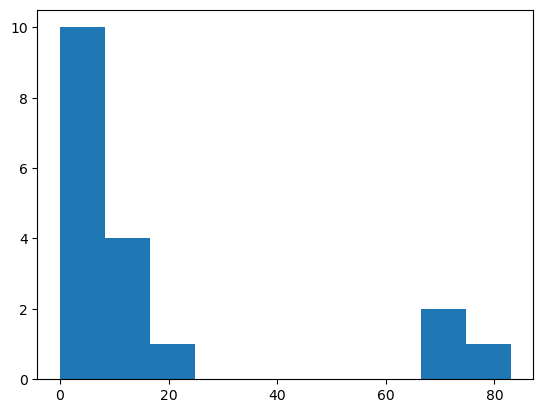

In [180]:
df1_missing = pd.DataFrame(df1.isna().sum()).reset_index(drop=False).rename(columns={'index':'col',0:'missing'})
df1_missing['missing_perc'] = df1_missing['missing'].divide(df1.shape[0])*100
plt.hist(df1_missing['missing_perc'])

In [181]:
df1_missing.columns

Index(['col', 'missing', 'missing_perc'], dtype='object')

In [182]:
df1_missing.shape

(18, 3)

In [183]:
df1_missing[df1_missing['missing_perc']>80].shape

(1, 3)

In [184]:
df1_missing[df1_missing['missing_perc']>80]['col'].to_list()

['ROE']

In [185]:
missing_cols_drop = df1_missing[df1_missing['missing_perc']>80]['col'].to_list()
df1.drop(columns=missing_cols_drop,inplace=True)
df1.reset_index(drop=True,inplace=True)

C:\Users\35098\AppData\Local\Temp\ipykernel_12560\3076753156.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1.drop(columns=missing_cols_drop,inplace=True)


In [186]:
df1.head()

,Ticker,Quarter,SMR,TMR,Volatility,Std,Momentum,Beta,Alpha,EP,BP,SP,Dividend_Flag,DE,EPS,Zscore,Target
0,reliance,Q4FY05,5.388004,1.501305,10.147323,1.278443,0.70,0.545504,0.004054,NaN,NaN,NaN,1,NaN,NaN,-0.416962,0.0
1,reliance,Q1FY06,20.361842,49.591169,17.226768,2.170369,5.49,0.997255,0.130998,NaN,NaN,NaN,1,NaN,NaN,-0.422182,NaN
2,reliance,Q2FY06,45.305466,53.134531,21.182862,2.668790,8.60,0.818094,0.023372,NaN,NaN,NaN,1,NaN,NaN,-0.316829,0.0
3,reliance,Q3FY06,38.398470,66.578947,18.261520,2.300735,5.45,0.898060,0.061364,NaN,NaN,NaN,0,NaN,NaN,-0.270389,1.0
4,reliance,Q4FY06,98.539500,188.488746,97.900865,12.334350,39.08,-0.778503,0.802280,NaN,NaN,NaN,1,NaN,NaN,0.283288,1.0


In [187]:
df1['Quarter'] = df1['Quarter'].apply(convert_qtr_to_date)
df1['Quarter'] = pd.to_datetime(df1['Quarter'],dayfirst=True)

C:\Users\35098\AppData\Local\Temp\ipykernel_12560\1817775498.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1['Quarter'] = df1['Quarter'].apply(convert_qtr_to_date)
C:\Users\35098\AppData\Local\Temp\ipykernel_12560\1817775498.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1['Quarter'] = pd.to_datetime(df1['Quarter'],dayfirst=True)


In [188]:
all_dates1 = df1['Quarter'].unique()
all_dates1 = pd.Series(all_dates1)
all_dates1.is_monotonic_increasing

True

In [189]:
all_dates1.sort_values(inplace=True)

In [190]:
all_dates1.reset_index(drop=True,inplace=True)

In [191]:
train_ind1 = int(len(all_dates1)*(1-test_size))
train_dates1 = all_dates1[:train_ind1]

In [192]:
len(train_dates1)

68

In [193]:
df1['Set'] = np.where(df1['Quarter'].isin(train_dates1),"Train",'Test')

C:\Users\35098\AppData\Local\Temp\ipykernel_12560\3796843214.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1['Set'] = np.where(df1['Quarter'].isin(train_dates1),"Train",'Test')


In [194]:
df1.columns

Index(['Ticker', 'Quarter', 'SMR', 'TMR', 'Volatility', 'Std', 'Momentum',
       'Beta', 'Alpha', 'EP', 'BP', 'SP', 'Dividend_Flag', 'DE', 'EPS',
       'Zscore', 'Target', 'Set'],
      dtype='object')

In [195]:
df_train1 = df1[df1['Set']=='Train']
df_test1 = df1[df1['Set']=='Test']

In [196]:
iv_cols1 = list(df1.columns)
misc_cols = ['Ticker','Quarter','Target','Set']
for col in misc_cols:
    iv_cols1.remove(col)

In [197]:
iv_cols1

['SMR',
 'TMR',
 'Volatility',
 'Std',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore']

##### imputation

In [198]:
df_train1.columns

Index(['Ticker', 'Quarter', 'SMR', 'TMR', 'Volatility', 'Std', 'Momentum',
       'Beta', 'Alpha', 'EP', 'BP', 'SP', 'Dividend_Flag', 'DE', 'EPS',
       'Zscore', 'Target', 'Set'],
      dtype='object')

In [199]:
iv_cols1

['SMR',
 'TMR',
 'Volatility',
 'Std',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore']

In [200]:
df_train1['Year'] = df_train1['Quarter'].dt.year
df_train1['Quarter_number'] = df_train1['Quarter'].dt.quarter

df_test1['Year'] = df_test1['Quarter'].dt.year
df_test1['Quarter_number'] = df_test1['Quarter'].dt.quarter

C:\Users\35098\AppData\Local\Temp\ipykernel_12560\3884832995.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train1['Year'] = df_train1['Quarter'].dt.year
C:\Users\35098\AppData\Local\Temp\ipykernel_12560\3884832995.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train1['Quarter_number'] = df_train1['Quarter'].dt.quarter
C:\Users\35098\AppData\Local\Temp\ipykernel_12560\3884832995.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[r

In [201]:
df_train1 = df_train1.set_index(['Quarter'])
df_test1 = df_test1.set_index(['Quarter'])

In [202]:
for col in iv_cols1:
    df_train1.loc[:,col] = df_train1[col].astype(float)
    df_test1.loc[:,col] = df_test1[col].astype(float)
    df_train1.loc[:,col] = df_train1.groupby('Ticker')[col].transform(lambda group: group.interpolate(method='time',limit_direction='forward'))
    df_test1.loc[:,col] = df_test1.groupby('Ticker')[col].transform(lambda group: group.interpolate(method='time',limit_direction='forward'))

In [203]:
df_train1.isna().sum()

Ticker                0
SMR                 768
TMR                1455
Volatility           38
Std                  38
Momentum            428
Beta                 47
Alpha                63
EP                 5485
BP                 4470
SP                 5081
Dividend_Flag         0
DE                 5082
EPS                4792
Zscore              363
Target            30107
Set                   0
Year                  0
Quarter_number        0
dtype: int64

In [204]:
df_train1.reset_index(inplace=True)
df_test1.reset_index(inplace=True)

In [205]:
for col in iv_cols1:
    df_train1.loc[:,col] = df_train1.groupby('Quarter')[col].transform(lambda group: group.fillna(group.median()))
    df_test1.loc[:,col] = df_test1.groupby('Quarter')[col].transform(lambda group: group.fillna(group.median()))

In [206]:
# df_test.isna().sum()

In [207]:
df_train1.fillna({'Target':0},inplace=True)
df_test1.fillna({'Target':0},inplace=True)

In [208]:
df_train1['Ticker'].nunique()

842

In [209]:
df_train1['Year'] = df_train1['Quarter'].dt.year
df_train1['Quarter_number'] = df_train1['Quarter'].dt.quarter

df_test1['Year'] = df_test1['Quarter'].dt.year
df_test1['Quarter_number'] = df_test1['Quarter'].dt.quarter

##### Multi-collinearity check

In [210]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [211]:
iv_cols1

['SMR',
 'TMR',
 'Volatility',
 'Std',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore']

In [212]:
iv_cols1 = iv_cols1 + ['Year','Quarter_number']

In [213]:
vif_data1 = pd.DataFrame()
vif_data1["feature"] = iv_cols1

In [214]:
df_train1[iv_cols1].isin([np.inf,-np.inf]).sum()

SMR               0
TMR               0
Volatility        0
Std               0
Momentum          0
Beta              0
Alpha             0
EP                0
BP                4
SP                0
Dividend_Flag     0
DE                0
EPS               0
Zscore            0
Year              0
Quarter_number    0
dtype: int64

In [215]:
df_train1.replace([np.inf,-np.inf],0,inplace=True)

In [216]:
for col in iv_cols1:
    df_train1.loc[:,col] = df_train1[col].astype(float)

In [217]:
df_train1.isna().sum()

Quarter           0
Ticker            0
SMR               0
TMR               0
Volatility        0
Std               0
Momentum          0
Beta              0
Alpha             0
EP                0
BP                0
SP                0
Dividend_Flag     0
DE                0
EPS               0
Zscore            0
Target            0
Set               0
Year              0
Quarter_number    0
dtype: int64

In [218]:
df_train1.fillna(0,inplace=True)

In [219]:
vif_data1["VIF"] = [variance_inflation_factor(df_train1[iv_cols1].values, i) for i in range(len(iv_cols1))]

d:\.conda\envs\qf_3\lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)
d:\.conda\envs\qf_3\lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


In [220]:
vif_data1.head()

,feature,VIF
0,SMR,2.165208
1,TMR,1.784312
2,Volatility,inf
3,Std,inf
4,Momentum,1.137886


In [221]:
vif_cols1 = vif_data1[vif_data1['VIF']<5]['feature'].to_list()
vif_cols1

['SMR',
 'TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore']

In [222]:
import seaborn as sns

In [223]:
# ax = sns.heatmap(df_fin1[vif_cols].corr(), annot=True)
df_train1[vif_cols1+['Target']].corr().style.background_gradient(cmap='coolwarm')

,SMR,TMR,Momentum,Beta,Alpha,EP,BP,SP,Dividend_Flag,DE,EPS,Zscore,Target
SMR,1.000000,0.618289,0.095781,0.002300,0.554576,-0.047648,-0.059561,-0.015140,-0.061651,0.000101,0.004217,0.004320,0.059325
TMR,0.618289,1.000000,0.068798,0.020233,0.379816,-0.054935,-0.067849,-0.017313,-0.053217,-0.002438,0.004584,0.011130,0.060492
Momentum,0.095781,0.068798,1.000000,-0.012535,0.127302,-0.019639,-0.020961,-0.004947,0.010908,-0.003279,0.114551,0.138058,-0.006710
Beta,0.002300,0.020233,-0.012535,1.000000,0.029028,0.021415,0.033723,0.017322,-0.055045,0.018479,-0.022897,-0.082300,-0.009290
Alpha,0.554576,0.379816,0.127302,0.029028,1.000000,-0.022789,-0.035381,-0.009932,-0.037380,0.003394,0.009621,0.007372,0.045138
EP,-0.047648,-0.054935,-0.019639,0.021415,-0.022789,1.000000,0.172338,0.060601,-0.084868,0.404259,-0.104213,-0.083788,0.034849
BP,-0.059561,-0.067849,-0.020961,0.033723,-0.035381,0.172338,1.000000,0.343232,-0.082965,-0.008510,-0.022250,-0.093219,0.028183
SP,-0.015140,-0.017313,-0.004947,0.017322,-0.009932,0.060601,0.343232,1.000000,-0.024547,0.009292,-0.016909,-0.024179,-0.001119
Dividend_Flag,-0.061651,-0.053217,0.010908,-0.055045,-0.037380,-0.084868,-0.082965,-0.024547,1.000000,-0.075037,0.062674,0.139769,-0.072040
DE,0.000101,-0.002438,-0.003279,0.018479,0.003394,0.404259,-0.008510,0.009292,-0.075037,1.000000,-0.015131,-0.026812,0.007971


In [224]:
for col in ['SMR']:
# for col in ['EP']:
# for col in ['EP']:
    vif_cols1.remove(col)

In [225]:
# ax = sns.heatmap(df_fin1[vif_cols].corr(), annot=True)
df_train1[vif_cols1+['Target']].corr().style.background_gradient(cmap='coolwarm')

,TMR,Momentum,Beta,Alpha,EP,BP,SP,Dividend_Flag,DE,EPS,Zscore,Target
TMR,1.000000,0.068798,0.020233,0.379816,-0.054935,-0.067849,-0.017313,-0.053217,-0.002438,0.004584,0.011130,0.060492
Momentum,0.068798,1.000000,-0.012535,0.127302,-0.019639,-0.020961,-0.004947,0.010908,-0.003279,0.114551,0.138058,-0.006710
Beta,0.020233,-0.012535,1.000000,0.029028,0.021415,0.033723,0.017322,-0.055045,0.018479,-0.022897,-0.082300,-0.009290
Alpha,0.379816,0.127302,0.029028,1.000000,-0.022789,-0.035381,-0.009932,-0.037380,0.003394,0.009621,0.007372,0.045138
EP,-0.054935,-0.019639,0.021415,-0.022789,1.000000,0.172338,0.060601,-0.084868,0.404259,-0.104213,-0.083788,0.034849
BP,-0.067849,-0.020961,0.033723,-0.035381,0.172338,1.000000,0.343232,-0.082965,-0.008510,-0.022250,-0.093219,0.028183
SP,-0.017313,-0.004947,0.017322,-0.009932,0.060601,0.343232,1.000000,-0.024547,0.009292,-0.016909,-0.024179,-0.001119
Dividend_Flag,-0.053217,0.010908,-0.055045,-0.037380,-0.084868,-0.082965,-0.024547,1.000000,-0.075037,0.062674,0.139769,-0.072040
DE,-0.002438,-0.003279,0.018479,0.003394,0.404259,-0.008510,0.009292,-0.075037,1.000000,-0.015131,-0.026812,0.007971
EPS,0.004584,0.114551,-0.022897,0.009621,-0.104213,-0.022250,-0.016909,0.062674,-0.015131,1.000000,0.176983,-0.007330


In [226]:
sign_cols1 = ['Ticker','Quarter']+vif_cols1+['Target']

In [227]:
sign_cols1

['Ticker',
 'Quarter',
 'TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore',
 'Target']

In [228]:
test_size

0.15

In [229]:
from datetime import datetime
# print()
date1 = f"{datetime.today().date()}"
date1 = date1.replace("-","_")
print(date1)

2025_07_25


In [230]:
date1 = '2025_07_25'

In [231]:
df_test1['Quarter'].nunique()

12

In [232]:
test_yrs = (test_size*80)/4

In [233]:
test_yrs

3.0

In [234]:
df_train1[sign_cols1].to_excel(rf"D:\FY25-26\Quant Fund\Fund1\data\train_data_after_multicollinearity_correlation_{int(test_yrs)}yrs_test_size_time_based_split_{date1}.xlsx",index=False)
df_test1[sign_cols1].to_excel(rf"D:\FY25-26\Quant Fund\Fund1\data\test_data_after_multicollinearity_correlation_{int(test_yrs)}yrs_test_size_time_based_split_{date1}.xlsx",index=False)

### Fund - 2

#### Random split

In [837]:
test_size = 0.2

In [838]:
df = df_load.copy()

In [839]:
df['EP'] = 1/df['PE']
df['BP'] = 1/df['PB']
df['SP'] = 1/df['PS']

In [840]:
df.columns

Index(['Ticker', 'Quarter', 'DE', 'ROCE', 'ROE', 'ROA', 'PB', 'PE', 'Ast_TO',
       'NI_Growth', 'Volume_Growth', 'Mkt_Cap_Growth', 'EBITDA_Growth',
       '200_MVA_Growth', '50D_MVA_Growth', 'Revenue_Growth', 'Dividend_Growth',
       'Abn_Gain_Loss_Growth', 'Dividend_Flag', 'Abn_Gain_Loss_Flag',
       'Mkt_Cap', 'CFO', 'EV_EBITDA', 'ICR', 'Earnings_Growth', 'EPS', 'FCF',
       'PS', 'PEG', 'Std', 'Alpha', 'Volatility', 'Momentum', 'SMR', 'TMR',
       'Beta', 'Zscore', 'Price', 'Returns', 'Rank', 'Target', 'EP', 'BP',
       'SP'],
      dtype='object')

In [841]:
params_f2 = ['SMR','TMR','Volatility','Std','Momentum','Beta','Alpha','EP','BP','SP','Dividend_Flag','ROE','DE','EPS','Zscore','PEG','EV_EBITDA','FCF','ICR']

In [842]:
len(params_f2)

19

In [843]:
df2 = df[['Ticker','Quarter']+params_f2+['Target']]

##### Missing value Analysis

(array([11.,  3.,  2.,  0.,  0.,  0.,  0.,  2.,  3.,  1.]),
 array([ 0.        ,  9.49119447, 18.98238893, 28.4735834 , 37.96477786,
        47.45597233, 56.94716679, 66.43836126, 75.92955572, 85.42075019,
        94.91194466]),
 <BarContainer object of 10 artists>)

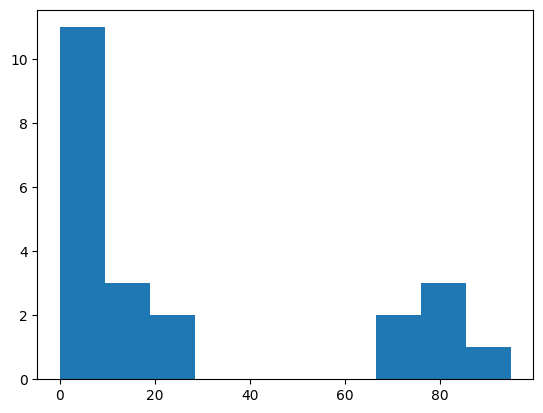

In [844]:
df2_missing = pd.DataFrame(df2.isna().sum()).reset_index(drop=False).rename(columns={'index':'col',0:'missing'})
df2_missing['missing_perc'] = df2_missing['missing'].divide(df2.shape[0])*100
plt.hist(df2_missing['missing_perc'])

In [845]:
df2_missing.columns

Index(['col', 'missing', 'missing_perc'], dtype='object')

In [846]:
df2_missing.shape

(22, 3)

In [847]:
df2_missing[df2_missing['missing_perc']>80].shape

(3, 3)

In [848]:
df2_missing[df2_missing['missing_perc']>80]['col'].to_list()

['ROE', 'PEG', 'EV_EBITDA']

In [849]:
missing_cols_drop = df2_missing[df2_missing['missing_perc']>80]['col'].to_list()
df2.drop(columns=missing_cols_drop,inplace=True)
df2.reset_index(drop=True,inplace=True)

C:\Users\35098\AppData\Local\Temp\ipykernel_17960\903494080.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2.drop(columns=missing_cols_drop,inplace=True)


In [850]:
df2.head()

,Ticker,Quarter,SMR,TMR,Volatility,Std,Momentum,Beta,Alpha,EP,BP,SP,Dividend_Flag,DE,EPS,Zscore,FCF,ICR,Target
0,reliance,Q4FY05,5.388004,1.501305,10.147323,1.278443,0.70,0.545504,0.004054,NaN,NaN,NaN,1,NaN,NaN,-0.416962,NaN,NaN,0.0
1,reliance,Q1FY06,20.361842,49.591169,17.226768,2.170369,5.49,0.997255,0.130998,NaN,NaN,NaN,1,NaN,NaN,-0.422182,NaN,NaN,NaN
2,reliance,Q2FY06,45.305466,53.134531,21.182862,2.668790,8.60,0.818094,0.023372,NaN,NaN,NaN,1,NaN,NaN,-0.316829,NaN,NaN,0.0
3,reliance,Q3FY06,38.398470,66.578947,18.261520,2.300735,5.45,0.898060,0.061364,NaN,NaN,NaN,0,NaN,NaN,-0.270389,NaN,NaN,1.0
4,reliance,Q4FY06,98.539500,188.488746,97.900865,12.334350,39.08,-0.778503,0.802280,NaN,NaN,NaN,1,NaN,NaN,0.283288,NaN,NaN,1.0


In [851]:
#### Considering 1st Random split
# test_size = 0.3
print(test_size)
split = 'Split1'
df_splits = pd.read_excel(rf'D:\FY25-26\Quant Fund\data\data_splits_07_06_2025_test_size_{test_size*100}%.xlsx',sheet_name=split)

0.2


In [852]:
df_splits.head()

,Quarter,Set
0,2017-12-31,Test
1,2018-12-31,Test
2,2013-09-30,Test
3,2007-09-30,Test
4,2020-09-30,Test


In [853]:
df_splits['Quarter'] = df_splits['Quarter'].astype(str)

In [854]:
df_splits.loc[:,'Quarter'] = df_splits['Quarter'].apply(get_financial_quarter)

In [855]:
df_fin_12 = df2.merge(df_splits,on='Quarter',how='left')
df_fin_12['Set'].isna().sum()

np.int64(0)

In [856]:
# df.fillna({'Target':0},inplace=True)

In [857]:
iv_cols2 = list(df_fin_12.columns)
misc_cols = ['Ticker','Quarter','Target','Set']
for col in misc_cols:
    iv_cols2.remove(col)

In [858]:
iv_cols2

['SMR',
 'TMR',
 'Volatility',
 'Std',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore',
 'FCF',
 'ICR']

In [859]:
df_fin_12['Quarter'] = df_fin_12['Quarter'].apply(convert_qtr_to_date)
df_fin_12['Quarter'] = pd.to_datetime(df_fin_12['Quarter'],dayfirst=True)

In [860]:
df_train2 = df_fin_12[df_fin_12['Set']=='Train']
df_test2 = df_fin_12[df_fin_12['Set']=='Test']

##### imputation

In [861]:
df_train2.columns

Index(['Ticker', 'Quarter', 'SMR', 'TMR', 'Volatility', 'Std', 'Momentum',
       'Beta', 'Alpha', 'EP', 'BP', 'SP', 'Dividend_Flag', 'DE', 'EPS',
       'Zscore', 'FCF', 'ICR', 'Target', 'Set'],
      dtype='object')

In [862]:
iv_cols2

['SMR',
 'TMR',
 'Volatility',
 'Std',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore',
 'FCF',
 'ICR']

In [863]:
df_train2.loc[:,'Quarter'] = pd.to_datetime(df_train2['Quarter'],dayfirst=True)
df_test2.loc[:,'Quarter'] = pd.to_datetime(df_test2['Quarter'],dayfirst=True)

In [864]:
df_train2 = df_train2.set_index(['Quarter'])
df_test2 = df_test2.set_index(['Quarter'])

In [865]:
iv_cols2

['SMR',
 'TMR',
 'Volatility',
 'Std',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore',
 'FCF',
 'ICR']

In [866]:
for col in iv_cols2:
    df_train2.loc[:,col] = df_train2[col].astype(float)
    df_test2.loc[:,col] = df_test2[col].astype(float)
    df_train2.loc[:,col] = df_train2.groupby('Ticker')[col].transform(lambda group: group.interpolate(method='time',limit_direction='forward'))
    df_test2.loc[:,col] = df_test2.groupby('Ticker')[col].transform(lambda group: group.interpolate(method='time',limit_direction='forward'))

In [867]:
df_train2.isna().sum()

Ticker               0
SMR                767
TMR               1559
Volatility          35
Std                 35
Momentum           415
Beta                43
Alpha               75
EP                4558
BP                3722
SP                4113
Dividend_Flag        0
DE                4035
EPS               4299
Zscore             313
FCF               7116
ICR               8990
Target           30743
Set                  0
dtype: int64

In [868]:
df_train2.reset_index(inplace=True)
df_test2.reset_index(inplace=True)

In [869]:
for col in iv_cols2:
    df_train2.loc[:,col] = df_train2.groupby('Quarter')[col].transform(lambda group: group.fillna(group.median()))
    df_test2.loc[:,col] = df_test2.groupby('Quarter')[col].transform(lambda group: group.fillna(group.median()))

In [870]:
df_test2.isna().sum()

Quarter             0
Ticker              0
SMR                 0
TMR                 0
Volatility          0
Std                 0
Momentum            0
Beta                0
Alpha               0
EP                  0
BP                  0
SP                  0
Dividend_Flag       0
DE                  0
EPS                 0
Zscore              0
FCF                 0
ICR                 0
Target           7826
Set                 0
dtype: int64

In [871]:
df_train2.fillna({'Target':0},inplace=True)
df_test2.fillna({'Target':0},inplace=True)

In [872]:
df_train2['Ticker'].nunique()

942

In [873]:
df_train2['Year'] = df_train2['Quarter'].dt.year
df_train2['Quarter_number'] = df_train2['Quarter'].dt.quarter

df_test2['Year'] = df_test2['Quarter'].dt.year
df_test2['Quarter_number'] = df_test2['Quarter'].dt.quarter

##### Multi-collinearity check

In [874]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [875]:
iv_cols2

['SMR',
 'TMR',
 'Volatility',
 'Std',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore',
 'FCF',
 'ICR']

In [876]:
iv_cols2 = iv_cols2 + ['Year','Quarter_number']

In [877]:
vif_data2 = pd.DataFrame()
vif_data2["feature"] = iv_cols2

In [878]:
df_train2[iv_cols2].isin([np.inf,-np.inf]).sum()

SMR               0
TMR               0
Volatility        0
Std               0
Momentum          0
Beta              0
Alpha             0
EP                0
BP                4
SP                0
Dividend_Flag     0
DE                0
EPS               0
Zscore            0
FCF               0
ICR               0
Year              0
Quarter_number    0
dtype: int64

In [879]:
df_train2.replace([np.inf,-np.inf],0,inplace=True)

In [880]:
for col in iv_cols2:
    df_train2.loc[:,col] = df_train2[col].astype(float)

In [881]:
df_train2.isna().sum()

Quarter           0
Ticker            0
SMR               0
TMR               0
Volatility        0
Std               0
Momentum          0
Beta              0
Alpha             0
EP                0
BP                0
SP                0
Dividend_Flag     0
DE                0
EPS               0
Zscore            0
FCF               0
ICR               0
Target            0
Set               0
Year              0
Quarter_number    0
dtype: int64

In [882]:
df_train2.fillna(0,inplace=True)

In [883]:
vif_data2["VIF"] = [variance_inflation_factor(df_train2[iv_cols2].values, i) for i in range(len(iv_cols2))]

d:\Quant Fund\qf_33\lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)
d:\Quant Fund\qf_33\lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


In [884]:
vif_data2.head()

,feature,VIF
0,SMR,1.916895
1,TMR,1.214567
2,Volatility,inf
3,Std,inf
4,Momentum,1.176761


In [885]:
vif_cols2 = vif_data2[vif_data2['VIF']<5]['feature'].to_list()
vif_cols2

['SMR',
 'TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore',
 'FCF',
 'ICR']

In [886]:
import seaborn as sns

In [887]:
# ax = sns.heatmap(df_fin2[vif_cols].corr(), annot=True)
df_train2[vif_cols2+['Target']].corr().style.background_gradient(cmap='coolwarm')

,SMR,TMR,Momentum,Beta,Alpha,EP,BP,SP,Dividend_Flag,DE,EPS,Zscore,FCF,ICR,Target
SMR,1.000000,0.386272,0.120195,0.030032,0.604534,-0.054198,0.003657,-0.016304,-0.052353,-0.002624,-0.001828,0.009052,0.012931,-0.000263,0.070847
TMR,0.386272,1.000000,0.040666,0.008377,0.213414,-0.029592,0.001736,-0.008274,-0.046076,-0.002666,-0.003500,-0.002566,0.006390,-0.001172,0.038261
Momentum,0.120195,0.040666,1.000000,-0.004517,0.163687,-0.022435,-0.001920,-0.005152,0.014601,-0.001450,0.234925,0.163580,0.001718,-0.000383,-0.002725
Beta,0.030032,0.008377,-0.004517,1.000000,-0.001367,0.025256,0.004486,0.012263,-0.057794,0.019014,-0.028479,-0.088761,0.004339,-0.003767,0.000732
Alpha,0.604534,0.213414,0.163687,-0.001367,1.000000,-0.029972,-0.002998,-0.011241,-0.043339,0.002385,-0.002708,0.006365,0.010684,-0.003456,0.062352
EP,-0.054198,-0.029592,-0.022435,0.025256,-0.029972,1.000000,0.022912,0.061213,-0.089884,0.435414,-0.037051,-0.086818,-0.010507,-0.001445,0.035260
BP,0.003657,0.001736,-0.001920,0.004486,-0.002998,0.022912,1.000000,0.047103,-0.023589,-0.001862,-0.004387,-0.012231,-0.018327,-0.000842,0.017270
SP,-0.016304,-0.008274,-0.005152,0.012263,-0.011241,0.061213,0.047103,1.000000,-0.027380,0.006761,-0.017967,-0.024667,-0.124798,-0.002239,-0.000051
Dividend_Flag,-0.052353,-0.046076,0.014601,-0.057794,-0.043339,-0.089884,-0.023589,-0.027380,1.000000,-0.088359,0.081276,0.137404,0.026478,0.020699,-0.070601
DE,-0.002624,-0.002666,-0.001450,0.019014,0.002385,0.435414,-0.001862,0.006761,-0.088359,1.000000,-0.019848,-0.023188,-0.014489,-0.003160,0.002028


In [888]:
for col in ['SMR']:
    vif_cols2.remove(col)

In [889]:
# ax = sns.heatmap(df_fin2[vif_cols].corr(), annot=True)
df_train2[vif_cols2+['Target']].corr().style.background_gradient(cmap='coolwarm')

,TMR,Momentum,Beta,Alpha,EP,BP,SP,Dividend_Flag,DE,EPS,Zscore,FCF,ICR,Target
TMR,1.000000,0.040666,0.008377,0.213414,-0.029592,0.001736,-0.008274,-0.046076,-0.002666,-0.003500,-0.002566,0.006390,-0.001172,0.038261
Momentum,0.040666,1.000000,-0.004517,0.163687,-0.022435,-0.001920,-0.005152,0.014601,-0.001450,0.234925,0.163580,0.001718,-0.000383,-0.002725
Beta,0.008377,-0.004517,1.000000,-0.001367,0.025256,0.004486,0.012263,-0.057794,0.019014,-0.028479,-0.088761,0.004339,-0.003767,0.000732
Alpha,0.213414,0.163687,-0.001367,1.000000,-0.029972,-0.002998,-0.011241,-0.043339,0.002385,-0.002708,0.006365,0.010684,-0.003456,0.062352
EP,-0.029592,-0.022435,0.025256,-0.029972,1.000000,0.022912,0.061213,-0.089884,0.435414,-0.037051,-0.086818,-0.010507,-0.001445,0.035260
BP,0.001736,-0.001920,0.004486,-0.002998,0.022912,1.000000,0.047103,-0.023589,-0.001862,-0.004387,-0.012231,-0.018327,-0.000842,0.017270
SP,-0.008274,-0.005152,0.012263,-0.011241,0.061213,0.047103,1.000000,-0.027380,0.006761,-0.017967,-0.024667,-0.124798,-0.002239,-0.000051
Dividend_Flag,-0.046076,0.014601,-0.057794,-0.043339,-0.089884,-0.023589,-0.027380,1.000000,-0.088359,0.081276,0.137404,0.026478,0.020699,-0.070601
DE,-0.002666,-0.001450,0.019014,0.002385,0.435414,-0.001862,0.006761,-0.088359,1.000000,-0.019848,-0.023188,-0.014489,-0.003160,0.002028
EPS,-0.003500,0.234925,-0.028479,-0.002708,-0.037051,-0.004387,-0.017967,0.081276,-0.019848,1.000000,0.316263,0.027918,0.002623,-0.016353


In [890]:
sign_cols2 = ['Ticker','Quarter']+vif_cols2+['Target']

In [891]:
sign_cols2

['Ticker',
 'Quarter',
 'TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore',
 'FCF',
 'ICR',
 'Target']

In [892]:
split

'Split1'

In [893]:
test_size

0.2

In [894]:
from datetime import datetime
# print()
date1 = f"{datetime.today().date()}"
date1 = date1.replace("-","_")
print(date1)

2025_07_03


In [895]:
# df_train2[sign_cols2].to_excel(rf"D:\FY25-26\Quant Fund\Fund2\data\train_data_after_multicollinearity_correlation_{int(test_size*100)}_test_size_random_{split.lower()}_{date1}.xlsx",index=False)
# df_test2[sign_cols2].to_excel(rf"D:\FY25-26\Quant Fund\Fund2\data\test_data_after_multicollinearity_correlation_{int(test_size*100)}_test_size_random_{split.lower()}_{date1}.xlsx",index=False)

#### Time Based Split

In [627]:
test_size = 0.2

In [628]:
df = df_load.copy()

In [629]:
df.head()

,Ticker,Quarter,DE,ROCE,ROE,ROA,PB,PE,Ast_TO,NI_Growth,...,Volatility,Momentum,SMR,TMR,Beta,Zscore,Price,Returns,Rank,Target
0,reliance,Q4FY05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,10.147323,0.70,5.388004,1.501305,0.545504,-0.416962,31.10,0.176527,180.0,0.0
1,reliance,Q1FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,17.226768,5.49,20.361842,49.591169,0.997255,-0.422182,36.59,0.235037,225.0,NaN
2,reliance,Q2FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,21.182862,8.60,45.305466,53.134531,0.818094,-0.316829,45.19,0.120602,165.0,0.0
3,reliance,Q3FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,18.261520,5.45,38.398470,66.578947,0.898060,-0.270389,50.64,0.771722,22.0,1.0
4,reliance,Q4FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,97.900865,39.08,98.539500,188.488746,-0.778503,0.283288,89.72,0.332590,18.0,1.0


In [630]:
df['EP'] = 1/df['PE']
df['BP'] = 1/df['PB']
df['SP'] = 1/df['PS']

In [631]:
df.columns

Index(['Ticker', 'Quarter', 'DE', 'ROCE', 'ROE', 'ROA', 'PB', 'PE', 'Ast_TO',
       'NI_Growth', 'Volume_Growth', 'Mkt_Cap_Growth', 'EBITDA_Growth',
       '200_MVA_Growth', '50D_MVA_Growth', 'Revenue_Growth', 'Dividend_Growth',
       'Abn_Gain_Loss_Growth', 'Dividend_Flag', 'Abn_Gain_Loss_Flag',
       'Mkt_Cap', 'CFO', 'EV_EBITDA', 'ICR', 'Earnings_Growth', 'EPS', 'FCF',
       'PS', 'PEG', 'Std', 'Alpha', 'Volatility', 'Momentum', 'SMR', 'TMR',
       'Beta', 'Zscore', 'Price', 'Returns', 'Rank', 'Target', 'EP', 'BP',
       'SP'],
      dtype='object')

In [632]:
df['Abn_Gain_Loss_Flag'].value_counts()

Abn_Gain_Loss_Flag
-1.0    3604
 1.0    2665
Name: count, dtype: int64

In [633]:
df['Abn_Gain_Loss_Flag'].fillna(0,inplace=True)

C:\Users\35098\AppData\Local\Temp\ipykernel_17960\735944254.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Abn_Gain_Loss_Flag'].fillna(0,inplace=True)


In [634]:
df['Earnings_Growth'].describe()

d:\Quant Fund\qf_33\lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


count    3273.000000
mean             inf
std              NaN
min      -215.588542
25%        -0.223712
50%         0.025641
75%         0.199422
max              inf
Name: Earnings_Growth, dtype: float64

In [635]:
df['Earnings_Growth'].replace([np.inf,-np.inf,np.nan],0,inplace=True)

C:\Users\35098\AppData\Local\Temp\ipykernel_17960\2245785938.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Earnings_Growth'].replace([np.inf,-np.inf,np.nan],0,inplace=True)


In [636]:
df.shape

(53773, 44)

In [637]:
# df['EBITDA_Growth']
df[df['Ticker']=='reliance']['Revenue_Growth'].isna().sum()

np.int64(60)

In [638]:
df_check = df.set_index(keys=['Ticker']).groupby(by=['Ticker']).ffill()
df_check.reset_index(inplace=True)

In [639]:
df_check.head()

,Ticker,Quarter,DE,ROCE,ROE,ROA,PB,PE,Ast_TO,NI_Growth,...,TMR,Beta,Zscore,Price,Returns,Rank,Target,EP,BP,SP
0,reliance,Q4FY05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.501305,0.545504,-0.416962,31.10,0.176527,180.0,0.0,NaN,NaN,NaN
1,reliance,Q1FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,49.591169,0.997255,-0.422182,36.59,0.235037,225.0,0.0,NaN,NaN,NaN
2,reliance,Q2FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,53.134531,0.818094,-0.316829,45.19,0.120602,165.0,0.0,NaN,NaN,NaN
3,reliance,Q3FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,66.578947,0.898060,-0.270389,50.64,0.771722,22.0,1.0,NaN,NaN,NaN
4,reliance,Q4FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,188.488746,-0.778503,0.283288,89.72,0.332590,18.0,1.0,NaN,NaN,NaN


In [640]:
# df_check[df_check['Ticker']=='reliance'][~df_check[df_check['Ticker']=='reliance']['Revenue_Growth'].isna()]['Revenue_Growth']

In [641]:
df[df['Ticker']=='reliance'].shape

(80, 44)

In [642]:
df['EBITDA_Growth'].isna().sum()

np.int64(53621)

In [643]:
df.shape

(53773, 44)

In [644]:
df['Earnings_Growth_Flag'] = np.where(df['Earnings_Growth']>0,1,np.where(df['Earnings_Growth']<0,-1,0))

In [645]:
params_f2 = ['SMR','TMR','Volatility','Std','Momentum','Beta','Alpha','EP','BP','SP','Dividend_Flag','ROE','DE','EPS','Zscore','PEG','EV_EBITDA','FCF','ICR']

In [646]:
len(params_f2)

19

In [647]:
df2 = df[['Ticker','Quarter']+params_f2+['Target']]

##### Missing value Analysis

(array([11.,  3.,  2.,  0.,  0.,  0.,  0.,  2.,  3.,  1.]),
 array([ 0.        ,  9.49119447, 18.98238893, 28.4735834 , 37.96477786,
        47.45597233, 56.94716679, 66.43836126, 75.92955572, 85.42075019,
        94.91194466]),
 <BarContainer object of 10 artists>)

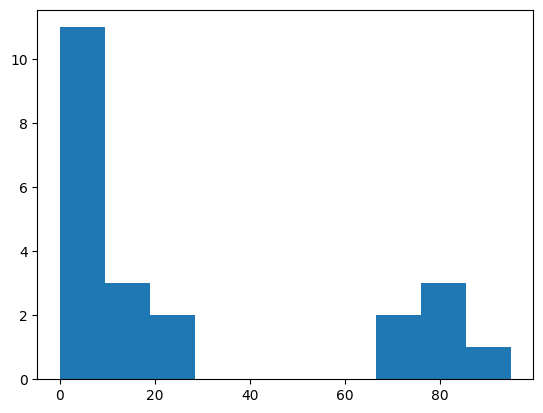

In [648]:
df2_missing = pd.DataFrame(df2.isna().sum()).reset_index(drop=False).rename(columns={'index':'col',0:'missing'})
df2_missing['missing_perc'] = df2_missing['missing'].divide(df2.shape[0])*100
plt.hist(df2_missing['missing_perc'])

In [649]:
df2_missing.columns

Index(['col', 'missing', 'missing_perc'], dtype='object')

In [650]:
df2_missing.shape

(22, 3)

In [651]:
df2_missing[df2_missing['missing_perc']>80].shape

(3, 3)

In [652]:
df2_missing[df2_missing['missing_perc']>80]['col'].to_list()

['ROE', 'PEG', 'EV_EBITDA']

In [653]:
missing_cols_drop = df2_missing[df2_missing['missing_perc']>80]['col'].to_list()
df2.drop(columns=missing_cols_drop,inplace=True)
df2.reset_index(drop=True,inplace=True)

C:\Users\35098\AppData\Local\Temp\ipykernel_17960\903494080.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2.drop(columns=missing_cols_drop,inplace=True)


In [654]:
df2.head()

,Ticker,Quarter,SMR,TMR,Volatility,Std,Momentum,Beta,Alpha,EP,BP,SP,Dividend_Flag,DE,EPS,Zscore,FCF,ICR,Target
0,reliance,Q4FY05,5.388004,1.501305,10.147323,1.278443,0.70,0.545504,0.004054,NaN,NaN,NaN,1,NaN,NaN,-0.416962,NaN,NaN,0.0
1,reliance,Q1FY06,20.361842,49.591169,17.226768,2.170369,5.49,0.997255,0.130998,NaN,NaN,NaN,1,NaN,NaN,-0.422182,NaN,NaN,NaN
2,reliance,Q2FY06,45.305466,53.134531,21.182862,2.668790,8.60,0.818094,0.023372,NaN,NaN,NaN,1,NaN,NaN,-0.316829,NaN,NaN,0.0
3,reliance,Q3FY06,38.398470,66.578947,18.261520,2.300735,5.45,0.898060,0.061364,NaN,NaN,NaN,0,NaN,NaN,-0.270389,NaN,NaN,1.0
4,reliance,Q4FY06,98.539500,188.488746,97.900865,12.334350,39.08,-0.778503,0.802280,NaN,NaN,NaN,1,NaN,NaN,0.283288,NaN,NaN,1.0


In [655]:
df2['Quarter'] = df2['Quarter'].apply(convert_qtr_to_date)
df2['Quarter'] = pd.to_datetime(df2['Quarter'],dayfirst=True)

C:\Users\35098\AppData\Local\Temp\ipykernel_17960\1186569962.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2['Quarter'] = df2['Quarter'].apply(convert_qtr_to_date)
C:\Users\35098\AppData\Local\Temp\ipykernel_17960\1186569962.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2['Quarter'] = pd.to_datetime(df2['Quarter'],dayfirst=True)


In [656]:
all_dates2 = df2['Quarter'].unique()
all_dates2 = pd.Series(all_dates2)
all_dates2.is_monotonic_increasing

True

In [657]:
all_dates2.sort_values(inplace=True)

In [658]:
all_dates2.reset_index(drop=True,inplace=True)

In [659]:
train_ind2 = int(len(all_dates2)*(1-test_size))
train_dates2 = all_dates2[:train_ind2]

In [660]:
df2['Set'] = np.where(df2['Quarter'].isin(train_dates2),"Train",'Test')

C:\Users\35098\AppData\Local\Temp\ipykernel_17960\3084120813.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2['Set'] = np.where(df2['Quarter'].isin(train_dates2),"Train",'Test')


In [661]:
df2.columns

Index(['Ticker', 'Quarter', 'SMR', 'TMR', 'Volatility', 'Std', 'Momentum',
       'Beta', 'Alpha', 'EP', 'BP', 'SP', 'Dividend_Flag', 'DE', 'EPS',
       'Zscore', 'FCF', 'ICR', 'Target', 'Set'],
      dtype='object')

In [662]:
df_train2 = df2[df2['Set']=='Train']
df_test2 = df2[df2['Set']=='Test']

In [663]:
iv_cols2 = list(df2.columns)
misc_cols = ['Ticker','Quarter','Target','Set']
for col in misc_cols:
    iv_cols2.remove(col)

In [664]:
iv_cols2

['SMR',
 'TMR',
 'Volatility',
 'Std',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore',
 'FCF',
 'ICR']

##### imputation

In [665]:
df_train2.columns

Index(['Ticker', 'Quarter', 'SMR', 'TMR', 'Volatility', 'Std', 'Momentum',
       'Beta', 'Alpha', 'EP', 'BP', 'SP', 'Dividend_Flag', 'DE', 'EPS',
       'Zscore', 'FCF', 'ICR', 'Target', 'Set'],
      dtype='object')

In [666]:
iv_cols2

['SMR',
 'TMR',
 'Volatility',
 'Std',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore',
 'FCF',
 'ICR']

In [667]:
df_train2['Year'] = df_train2['Quarter'].dt.year
df_train2['Quarter_number'] = df_train2['Quarter'].dt.quarter

df_test2['Year'] = df_test2['Quarter'].dt.year
df_test2['Quarter_number'] = df_test2['Quarter'].dt.quarter

C:\Users\35098\AppData\Local\Temp\ipykernel_17960\3385011752.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train2['Year'] = df_train2['Quarter'].dt.year
C:\Users\35098\AppData\Local\Temp\ipykernel_17960\3385011752.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train2['Quarter_number'] = df_train2['Quarter'].dt.quarter
C:\Users\35098\AppData\Local\Temp\ipykernel_17960\3385011752.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[r

In [668]:
df_train2 = df_train2.set_index(['Quarter'])
df_test2 = df_test2.set_index(['Quarter'])

In [669]:
for col in iv_cols2:
    df_train2.loc[:,col] = df_train2[col].astype(float)
    df_test2.loc[:,col] = df_test2[col].astype(float)
    df_train2.loc[:,col] = df_train2.groupby('Ticker')[col].transform(lambda group: group.interpolate(method='time',limit_direction='forward'))
    df_test2.loc[:,col] = df_test2.groupby('Ticker')[col].transform(lambda group: group.interpolate(method='time',limit_direction='forward'))

In [670]:
df_train2.isna().sum()

Ticker                0
SMR                 668
TMR                1290
Volatility           37
Std                  37
Momentum            372
Beta                 44
Alpha                60
EP                 5422
BP                 4429
SP                 5043
Dividend_Flag         0
DE                 5066
EPS                4702
Zscore              345
FCF                7377
ICR                8874
Target            27608
Set                   0
Year                  0
Quarter_number        0
dtype: int64

In [671]:
df_train2.reset_index(inplace=True)
df_test2.reset_index(inplace=True)

In [672]:
for col in iv_cols2:
    df_train2.loc[:,col] = df_train2.groupby('Quarter')[col].transform(lambda group: group.fillna(group.median()))
    df_test2.loc[:,col] = df_test2.groupby('Quarter')[col].transform(lambda group: group.fillna(group.median()))

In [673]:
# df_test.isna().sum()

In [674]:
df_train2.fillna({'Target':0},inplace=True)
df_test2.fillna({'Target':0},inplace=True)

In [675]:
df_train2['Ticker'].nunique()

786

In [676]:
df_train2['Year'] = df_train2['Quarter'].dt.year
df_train2['Quarter_number'] = df_train2['Quarter'].dt.quarter

df_test2['Year'] = df_test2['Quarter'].dt.year
df_test2['Quarter_number'] = df_test2['Quarter'].dt.quarter

##### Multi-collinearity check

In [677]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [678]:
iv_cols2

['SMR',
 'TMR',
 'Volatility',
 'Std',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore',
 'FCF',
 'ICR']

In [679]:
iv_cols2 = iv_cols2 + ['Year','Quarter_number']

In [680]:
vif_data2 = pd.DataFrame()
vif_data2["feature"] = iv_cols2

In [681]:
df_train2[iv_cols2].isin([np.inf,-np.inf]).sum()

SMR               0
TMR               0
Volatility        0
Std               0
Momentum          0
Beta              0
Alpha             0
EP                0
BP                4
SP                0
Dividend_Flag     0
DE                0
EPS               0
Zscore            0
FCF               0
ICR               0
Year              0
Quarter_number    0
dtype: int64

In [682]:
df_train2.replace([np.inf,-np.inf],0,inplace=True)

In [683]:
for col in iv_cols2:
    df_train2.loc[:,col] = df_train2[col].astype(float)

In [684]:
df_train2.isna().sum()

Quarter           0
Ticker            0
SMR               0
TMR               0
Volatility        0
Std               0
Momentum          0
Beta              0
Alpha             0
EP                0
BP                0
SP                0
Dividend_Flag     0
DE                0
EPS               0
Zscore            0
FCF               0
ICR               0
Target            0
Set               0
Year              0
Quarter_number    0
dtype: int64

In [685]:
df_train2.fillna(0,inplace=True)

In [686]:
vif_data2["VIF"] = [variance_inflation_factor(df_train2[iv_cols2].values, i) for i in range(len(iv_cols2))]

d:\Quant Fund\qf_33\lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)
d:\Quant Fund\qf_33\lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


In [687]:
vif_data2.head()

,feature,VIF
0,SMR,2.075841
1,TMR,1.692446
2,Volatility,inf
3,Std,inf
4,Momentum,1.122470


In [688]:
vif_cols2 = vif_data2[vif_data2['VIF']<5]['feature'].to_list()
vif_cols2

['SMR',
 'TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore',
 'FCF',
 'ICR']

In [689]:
import seaborn as sns

In [690]:
# ax = sns.heatmap(df_fin2[vif_cols].corr(), annot=True)
df_train2[vif_cols2+['Target']].corr().style.background_gradient(cmap='coolwarm')

,SMR,TMR,Momentum,Beta,Alpha,EP,BP,SP,Dividend_Flag,DE,EPS,Zscore,FCF,ICR,Target
SMR,1.000000,0.601243,0.089162,-0.000122,0.548046,-0.054153,-0.058358,-0.014657,-0.048681,-0.006048,0.005778,0.009565,0.012473,-0.006590,0.056826
TMR,0.601243,1.000000,0.061012,0.021814,0.369111,-0.057008,-0.067889,-0.016957,-0.033925,-0.008407,0.006244,0.019064,0.015239,-0.005829,0.057054
Momentum,0.089162,0.061012,1.000000,-0.013024,0.117331,-0.020054,-0.018664,-0.004404,0.013250,-0.003234,0.125526,0.129087,0.001644,-0.000456,-0.005282
Beta,-0.000122,0.021814,-0.013024,1.000000,0.037477,0.020471,0.031577,0.016696,-0.052411,0.018561,-0.020910,-0.079125,0.006477,-0.013179,-0.009949
Alpha,0.548046,0.369111,0.117331,0.037477,1.000000,-0.031867,-0.036043,-0.009927,-0.029410,0.000191,0.012849,0.010960,0.011651,-0.004414,0.046098
EP,-0.054153,-0.057008,-0.020054,0.020471,-0.031867,1.000000,0.173599,0.060552,-0.087584,0.379816,-0.105853,-0.083113,-0.018360,-0.006021,0.031015
BP,-0.058358,-0.067889,-0.018664,0.031577,-0.036043,0.173599,1.000000,0.349208,-0.082372,-0.007602,-0.030016,-0.090905,-0.164266,-0.007312,0.027350
SP,-0.014657,-0.016957,-0.004404,0.016696,-0.009927,0.060552,0.349208,1.000000,-0.024891,0.009961,-0.018717,-0.024336,-0.119302,-0.002240,-0.001554
Dividend_Flag,-0.048681,-0.033925,0.013250,-0.052411,-0.029410,-0.087584,-0.082372,-0.024891,1.000000,-0.072909,0.062162,0.143228,0.031909,0.017139,-0.072045
DE,-0.006048,-0.008407,-0.003234,0.018561,0.000191,0.379816,-0.007602,0.009961,-0.072909,1.000000,-0.013996,-0.029015,-0.020471,-0.002851,0.004021


In [691]:
for col in ['SMR']:
# for col in ['EP']:
# for col in ['EP']:
    vif_cols2.remove(col)

In [692]:
# ax = sns.heatmap(df_fin2[vif_cols].corr(), annot=True)
df_train2[vif_cols2+['Target']].corr().style.background_gradient(cmap='coolwarm')

,TMR,Momentum,Beta,Alpha,EP,BP,SP,Dividend_Flag,DE,EPS,Zscore,FCF,ICR,Target
TMR,1.000000,0.061012,0.021814,0.369111,-0.057008,-0.067889,-0.016957,-0.033925,-0.008407,0.006244,0.019064,0.015239,-0.005829,0.057054
Momentum,0.061012,1.000000,-0.013024,0.117331,-0.020054,-0.018664,-0.004404,0.013250,-0.003234,0.125526,0.129087,0.001644,-0.000456,-0.005282
Beta,0.021814,-0.013024,1.000000,0.037477,0.020471,0.031577,0.016696,-0.052411,0.018561,-0.020910,-0.079125,0.006477,-0.013179,-0.009949
Alpha,0.369111,0.117331,0.037477,1.000000,-0.031867,-0.036043,-0.009927,-0.029410,0.000191,0.012849,0.010960,0.011651,-0.004414,0.046098
EP,-0.057008,-0.020054,0.020471,-0.031867,1.000000,0.173599,0.060552,-0.087584,0.379816,-0.105853,-0.083113,-0.018360,-0.006021,0.031015
BP,-0.067889,-0.018664,0.031577,-0.036043,0.173599,1.000000,0.349208,-0.082372,-0.007602,-0.030016,-0.090905,-0.164266,-0.007312,0.027350
SP,-0.016957,-0.004404,0.016696,-0.009927,0.060552,0.349208,1.000000,-0.024891,0.009961,-0.018717,-0.024336,-0.119302,-0.002240,-0.001554
Dividend_Flag,-0.033925,0.013250,-0.052411,-0.029410,-0.087584,-0.082372,-0.024891,1.000000,-0.072909,0.062162,0.143228,0.031909,0.017139,-0.072045
DE,-0.008407,-0.003234,0.018561,0.000191,0.379816,-0.007602,0.009961,-0.072909,1.000000,-0.013996,-0.029015,-0.020471,-0.002851,0.004021
EPS,0.006244,0.125526,-0.020910,0.012849,-0.105853,-0.030016,-0.018717,0.062162,-0.013996,1.000000,0.166440,0.038715,0.003562,-0.006264


In [693]:
sign_cols2 = ['Ticker','Quarter']+vif_cols2+['Target']

In [694]:
sign_cols2

['Ticker',
 'Quarter',
 'TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore',
 'FCF',
 'ICR',
 'Target']

In [695]:
test_size

0.2

In [696]:
from datetime import datetime
# print()
date1 = f"{datetime.today().date()}"
date1 = date1.replace("-","_")
print(date1)

2025_07_03


In [697]:
df_train2[sign_cols2].to_excel(rf"D:\FY25-26\Quant Fund\Fund2\data\train_data_after_multicollinearity_correlation_{int(test_size*100)}_test_size_time_based_split_{date1}.xlsx",index=False)
df_test2[sign_cols2].to_excel(rf"D:\FY25-26\Quant Fund\Fund2\data\test_data_after_multicollinearity_correlation_{int(test_size*100)}_test_size_time_based_split_{date1}.xlsx",index=False)

### Fund - 3

#### Random Splits

In [63]:
df['EP'] = 1/df['PE']
df['BP'] = 1/df['PB']
df['SP'] = 1/df['PS']

In [64]:
df.columns

Index(['Ticker', 'Quarter', 'DE', 'ROCE', 'ROE', 'ROA', 'PB', 'PE', 'Ast_TO',
       'NI_Growth', 'Volume_Growth', 'Mkt_Cap_Growth', 'EBITDA_Growth',
       '200_MVA_Growth', '50D_MVA_Growth', 'Revenue_Growth', 'Dividend_Growth',
       'Abn_Gain_Loss_Growth', 'Dividend_Flag', 'Abn_Gain_Loss_Flag',
       'Mkt_Cap', 'CFO', 'EV_EBITDA', 'ICR', 'Earnings_Growth', 'EPS', 'FCF',
       'PS', 'PEG', 'Std', 'Alpha', 'Volatility', 'Momentum', 'SMR', 'TMR',
       'Beta', 'Zscore', 'Price', 'Returns', 'Rank', 'Target', 'EP', 'BP',
       'SP'],
      dtype='object')

In [65]:
df['Abn_Gain_Loss_Flag'].value_counts()

Abn_Gain_Loss_Flag
-1.0    3604
 1.0    2665
Name: count, dtype: int64

In [66]:
df['Abn_Gain_Loss_Flag'].fillna(0,inplace=True)

C:\Users\35098\AppData\Local\Temp\ipykernel_17960\735944254.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Abn_Gain_Loss_Flag'].fillna(0,inplace=True)


In [67]:
df['Earnings_Growth'].describe()

d:\Quant Fund\qf_33\lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


count    3273.000000
mean             inf
std              NaN
min      -215.588542
25%        -0.223712
50%         0.025641
75%         0.199422
max              inf
Name: Earnings_Growth, dtype: float64

In [68]:
df['Earnings_Growth'].replace([np.inf,-np.inf,np.nan],0,inplace=True)

C:\Users\35098\AppData\Local\Temp\ipykernel_17960\2245785938.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Earnings_Growth'].replace([np.inf,-np.inf,np.nan],0,inplace=True)


In [69]:
df.shape

(53773, 44)

In [70]:
# df.groupby(by=['Ticker'])

In [71]:
# df['EBITDA_Growth']
df[df['Ticker']=='reliance']['Revenue_Growth'].isna().sum()

np.int64(60)

In [72]:
df_check = df.set_index(keys=['Ticker']).groupby(by=['Ticker']).ffill()
df_check.reset_index(inplace=True)

In [73]:
df_check.head()

,Ticker,Quarter,DE,ROCE,ROE,ROA,PB,PE,Ast_TO,NI_Growth,...,TMR,Beta,Zscore,Price,Returns,Rank,Target,EP,BP,SP
0,reliance,Q4FY05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.501305,0.545504,-0.416962,31.10,0.176527,180.0,0.0,NaN,NaN,NaN
1,reliance,Q1FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,49.591169,0.997255,-0.422182,36.59,0.235037,225.0,0.0,NaN,NaN,NaN
2,reliance,Q2FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,53.134531,0.818094,-0.316829,45.19,0.120602,165.0,0.0,NaN,NaN,NaN
3,reliance,Q3FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,66.578947,0.898060,-0.270389,50.64,0.771722,22.0,1.0,NaN,NaN,NaN
4,reliance,Q4FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,188.488746,-0.778503,0.283288,89.72,0.332590,18.0,1.0,NaN,NaN,NaN


In [74]:
# df_check[df_check['Ticker']=='reliance'][~df_check[df_check['Ticker']=='reliance']['Revenue_Growth'].isna()]['Revenue_Growth']

In [75]:
df[df['Ticker']=='reliance'].shape

(80, 44)

In [76]:
df['EBITDA_Growth'].isna().sum()

np.int64(53621)

In [77]:
df.shape

(53773, 44)

In [78]:
df['Earnings_Growth_Flag'] = np.where(df['Earnings_Growth']>0,1,np.where(df['Earnings_Growth']<0,-1,0))

In [79]:
params_f3 = [
    # 'Volatility', -- dropped as per CEO sir's directions
    'SMR','TMR','Std','Momentum','Beta','Alpha','EP','BP','SP',
    'DE',  'ROE',  'Dividend_Growth','Dividend_Flag','EPS','Earnings_Growth','Earnings_Growth_Flag','Zscore',
    'PEG','EV_EBITDA','FCF','ICR',
    'Revenue_Growth','NI_Growth','CFO', 'Ast_TO' ,'ROCE','ROA',
    '200_MVA_Growth', '50D_MVA_Growth', 
    'Volume_Growth', 'Abn_Gain_Loss_Growth', 'Abn_Gain_Loss_Flag',
    'EBITDA_Growth','Mkt_Cap_Growth'
    ]

In [80]:
len(params_f3)

34

In [81]:
df3 = df[['Ticker','Quarter']+params_f3+['Target']]

##### Missing value Analysis

(array([18.,  3.,  2.,  0.,  0.,  0.,  0.,  3.,  6.,  5.]),
 array([ 0.        ,  9.97173303, 19.94346605, 29.91519908, 39.8869321 ,
        49.85866513, 59.83039816, 69.80213118, 79.77386421, 89.74559723,
        99.71733026]),
 <BarContainer object of 10 artists>)

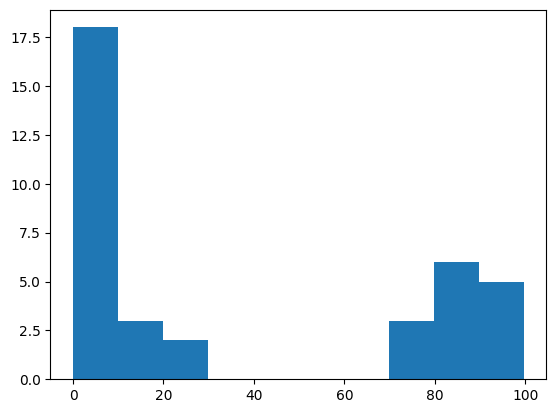

In [82]:
df3_missing = pd.DataFrame(df3.isna().sum()).reset_index(drop=False).rename(columns={'index':'col',0:'missing'})
df3_missing['missing_perc'] = df3_missing['missing'].divide(df3.shape[0])*100
plt.hist(df3_missing['missing_perc'])

In [83]:
df3_missing.columns

Index(['col', 'missing', 'missing_perc'], dtype='object')

In [84]:
df3_missing.shape

(37, 3)

In [85]:
df3_missing[df3_missing['missing_perc']>80].shape

(11, 3)

In [86]:
df3_missing[df3_missing['missing_perc']>80]['col'].to_list()

['ROE',
 'PEG',
 'EV_EBITDA',
 'Revenue_Growth',
 'NI_Growth',
 'CFO',
 'Ast_TO',
 'ROCE',
 'ROA',
 'Abn_Gain_Loss_Growth',
 'EBITDA_Growth']

In [87]:
missing_cols_drop = df3_missing[df3_missing['missing_perc']>80]['col'].to_list()
df3.drop(columns=missing_cols_drop,inplace=True)
df3.reset_index(drop=True,inplace=True)

C:\Users\35098\AppData\Local\Temp\ipykernel_17960\3096015063.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df3.drop(columns=missing_cols_drop,inplace=True)


In [88]:
df3.head()

,Ticker,Quarter,SMR,TMR,Std,Momentum,Beta,Alpha,EP,BP,...,Earnings_Growth_Flag,Zscore,FCF,ICR,200_MVA_Growth,50D_MVA_Growth,Volume_Growth,Abn_Gain_Loss_Flag,Mkt_Cap_Growth,Target
0,reliance,Q4FY05,5.388004,1.501305,1.278443,0.70,0.545504,0.004054,NaN,NaN,...,0,-0.416962,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0
1,reliance,Q1FY06,20.361842,49.591169,2.170369,5.49,0.997255,0.130998,NaN,NaN,...,0,-0.422182,NaN,NaN,NaN,NaN,NaN,0.0,0.176724,NaN
2,reliance,Q2FY06,45.305466,53.134531,2.668790,8.60,0.818094,0.023372,NaN,NaN,...,0,-0.316829,NaN,NaN,0.66768,9.082328,2.488304,0.0,0.235001,0.0
3,reliance,Q3FY06,38.398470,66.578947,2.300735,5.45,0.898060,0.061364,NaN,NaN,...,0,-0.270389,NaN,NaN,NaN,NaN,NaN,0.0,NaN,1.0
4,reliance,Q4FY06,98.539500,188.488746,12.334350,39.08,-0.778503,0.802280,NaN,NaN,...,0,0.283288,NaN,NaN,NaN,NaN,NaN,0.0,NaN,1.0


In [138]:
#### Considering 1st Random split
test_size = 0.2
print(test_size)
split = 'Split1'
df_splits = pd.read_excel(rf'D:\FY25-26\Quant Fund\data\data_splits_07_06_2025_test_size_{test_size*100}%.xlsx',sheet_name=split)

0.2


In [139]:
df_splits.head()

,Quarter,Set
0,2017-12-31,Test
1,2018-12-31,Test
2,2013-09-30,Test
3,2007-09-30,Test
4,2020-09-30,Test


In [140]:
df_splits['Quarter'] = df_splits['Quarter'].astype(str)

In [141]:
df_splits.loc[:,'Quarter'] = df_splits['Quarter'].apply(get_financial_quarter)

In [142]:
df_fin_13 = df3.merge(df_splits,on='Quarter',how='left')
df_fin_13['Set'].isna().sum()

np.int64(0)

In [143]:
# df.fillna({'Target':0},inplace=True)

In [144]:
iv_cols3 = list(df_fin_13.columns)
misc_cols = ['Ticker','Quarter','Target','Set']
for col in misc_cols:
    iv_cols3.remove(col)

In [145]:
iv_cols3

['SMR',
 'TMR',
 'Std',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'DE',
 'Dividend_Growth',
 'Dividend_Flag',
 'EPS',
 'Earnings_Growth',
 'Earnings_Growth_Flag',
 'Zscore',
 'FCF',
 'ICR',
 '200_MVA_Growth',
 '50D_MVA_Growth',
 'Volume_Growth',
 'Abn_Gain_Loss_Flag',
 'Mkt_Cap_Growth']

In [146]:
df_fin_13['Quarter'] = df_fin_13['Quarter'].apply(convert_qtr_to_date)
df_fin_13['Quarter'] = pd.to_datetime(df_fin_13['Quarter'],dayfirst=True)

In [147]:
df_train3 = df_fin_13[df_fin_13['Set']=='Train']
df_test3 = df_fin_13[df_fin_13['Set']=='Test']

##### imputation

In [148]:
df_train3.columns

Index(['Ticker', 'Quarter', 'SMR', 'TMR', 'Std', 'Momentum', 'Beta', 'Alpha',
       'EP', 'BP', 'SP', 'DE', 'Dividend_Growth', 'Dividend_Flag', 'EPS',
       'Earnings_Growth', 'Earnings_Growth_Flag', 'Zscore', 'FCF', 'ICR',
       '200_MVA_Growth', '50D_MVA_Growth', 'Volume_Growth',
       'Abn_Gain_Loss_Flag', 'Mkt_Cap_Growth', 'Target', 'Set'],
      dtype='object')

In [149]:
iv_cols3

['SMR',
 'TMR',
 'Std',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'DE',
 'Dividend_Growth',
 'Dividend_Flag',
 'EPS',
 'Earnings_Growth',
 'Earnings_Growth_Flag',
 'Zscore',
 'FCF',
 'ICR',
 '200_MVA_Growth',
 '50D_MVA_Growth',
 'Volume_Growth',
 'Abn_Gain_Loss_Flag',
 'Mkt_Cap_Growth']

In [150]:
df_train3.loc[:,'Quarter'] = pd.to_datetime(df_train3['Quarter'],dayfirst=True)
df_test3.loc[:,'Quarter'] = pd.to_datetime(df_test3['Quarter'],dayfirst=True)

In [151]:
df_train3 = df_train3.set_index(['Quarter'])
df_test3 = df_test3.set_index(['Quarter'])

In [152]:
iv_cols3

['SMR',
 'TMR',
 'Std',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'DE',
 'Dividend_Growth',
 'Dividend_Flag',
 'EPS',
 'Earnings_Growth',
 'Earnings_Growth_Flag',
 'Zscore',
 'FCF',
 'ICR',
 '200_MVA_Growth',
 '50D_MVA_Growth',
 'Volume_Growth',
 'Abn_Gain_Loss_Flag',
 'Mkt_Cap_Growth']

In [153]:
for col in iv_cols3:
    df_train3.loc[:,col] = df_train3[col].astype(float)
    df_test3.loc[:,col] = df_test3[col].astype(float)
    df_train3.loc[:,col] = df_train3.groupby('Ticker')[col].transform(lambda group: group.interpolate(method='time',limit_direction='forward'))
    df_test3.loc[:,col] = df_test3.groupby('Ticker')[col].transform(lambda group: group.interpolate(method='time',limit_direction='forward'))

In [154]:
df_train3.isna().sum()

Ticker                      0
SMR                       767
TMR                      1559
Std                        35
Momentum                  415
Beta                       43
Alpha                      75
EP                       4558
BP                       3722
SP                       4113
DE                       4035
Dividend_Growth          6327
Dividend_Flag               0
EPS                      4299
Earnings_Growth             0
Earnings_Growth_Flag        0
Zscore                    313
FCF                      7116
ICR                      8990
200_MVA_Growth           3086
50D_MVA_Growth           2128
Volume_Growth            2127
Abn_Gain_Loss_Flag          0
Mkt_Cap_Growth           1169
Target                  30743
Set                         0
dtype: int64

In [155]:
df_train3.reset_index(inplace=True)
df_test3.reset_index(inplace=True)

In [156]:
for col in iv_cols3:
    df_train3.loc[:,col] = df_train3.groupby('Quarter')[col].transform(lambda group: group.fillna(group.median()))
    df_test3.loc[:,col] = df_test3.groupby('Quarter')[col].transform(lambda group: group.fillna(group.median()))

d:\Quant Fund\qf_33\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1241: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
d:\Quant Fund\qf_33\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1241: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
d:\Quant Fund\qf_33\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1241: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
d:\Quant Fund\qf_33\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1241: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
d:\Quant Fund\qf_33\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1241: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
d:\Quant Fund\qf_33\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1241: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepd

In [157]:
# df_test.isna().sum()

In [158]:
df_train3.fillna({'Target':0},inplace=True)
df_test3.fillna({'Target':0},inplace=True)

In [159]:
df_train3['Ticker'].nunique()

942

In [160]:
df_train3['Year'] = df_train3['Quarter'].dt.year
df_train3['Quarter_number'] = df_train3['Quarter'].dt.quarter

df_test3['Year'] = df_test3['Quarter'].dt.year
df_test3['Quarter_number'] = df_test3['Quarter'].dt.quarter

##### Multi-collinearity check

In [161]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [162]:
iv_cols3

['SMR',
 'TMR',
 'Std',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'DE',
 'Dividend_Growth',
 'Dividend_Flag',
 'EPS',
 'Earnings_Growth',
 'Earnings_Growth_Flag',
 'Zscore',
 'FCF',
 'ICR',
 '200_MVA_Growth',
 '50D_MVA_Growth',
 'Volume_Growth',
 'Abn_Gain_Loss_Flag',
 'Mkt_Cap_Growth']

In [163]:
iv_cols3 = iv_cols3 + ['Year','Quarter_number']

In [164]:
vif_data3 = pd.DataFrame()
vif_data3["feature"] = iv_cols3

In [165]:
df_train3[iv_cols3].isin([np.inf,-np.inf]).sum()

SMR                      0
TMR                      0
Std                      0
Momentum                 0
Beta                     0
Alpha                    0
EP                       0
BP                       4
SP                       0
DE                       0
Dividend_Growth          0
Dividend_Flag            0
EPS                      0
Earnings_Growth          0
Earnings_Growth_Flag     0
Zscore                   0
FCF                      0
ICR                      0
200_MVA_Growth          32
50D_MVA_Growth          54
Volume_Growth            5
Abn_Gain_Loss_Flag       0
Mkt_Cap_Growth           0
Year                     0
Quarter_number           0
dtype: int64

In [166]:
df_train3.replace([np.inf,-np.inf],0,inplace=True)

In [167]:
for col in iv_cols3:
    df_train3.loc[:,col] = df_train3[col].astype(float)

In [168]:
df_train3.isna().sum()

Quarter                   0
Ticker                    0
SMR                       0
TMR                       0
Std                       0
Momentum                  0
Beta                      0
Alpha                     0
EP                        0
BP                        0
SP                        0
DE                        0
Dividend_Growth         485
Dividend_Flag             0
EPS                       0
Earnings_Growth           0
Earnings_Growth_Flag      0
Zscore                    0
FCF                       0
ICR                       0
200_MVA_Growth          970
50D_MVA_Growth          970
Volume_Growth           970
Abn_Gain_Loss_Flag        0
Mkt_Cap_Growth          485
Target                    0
Set                       0
Year                      0
Quarter_number            0
dtype: int64

In [169]:
df_train3.fillna(0,inplace=True)

In [170]:
vif_data3["VIF"] = [variance_inflation_factor(df_train3[iv_cols3].values, i) for i in range(len(iv_cols3))]

In [171]:
vif_data3.head()

,feature,VIF
0,SMR,1.970170
1,TMR,1.214997
2,Std,2.225352
3,Momentum,1.177684
4,Beta,2.759764


In [172]:
vif_cols3 = vif_data3[vif_data3['VIF']<5]['feature'].to_list()
vif_cols3

['SMR',
 'TMR',
 'Std',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'DE',
 'Dividend_Growth',
 'Dividend_Flag',
 'EPS',
 'Earnings_Growth',
 'Earnings_Growth_Flag',
 'Zscore',
 'FCF',
 'ICR',
 '200_MVA_Growth',
 '50D_MVA_Growth',
 'Volume_Growth',
 'Abn_Gain_Loss_Flag',
 'Mkt_Cap_Growth']

In [173]:
import seaborn as sns

In [174]:
# ax = sns.heatmap(df_fin2[vif_cols].corr(), annot=True)
df_train3[vif_cols3+['Target']].corr().style.background_gradient(cmap='coolwarm')

,SMR,TMR,Std,Momentum,Beta,Alpha,EP,BP,SP,DE,Dividend_Growth,Dividend_Flag,EPS,Earnings_Growth,Earnings_Growth_Flag,Zscore,FCF,ICR,200_MVA_Growth,50D_MVA_Growth,Volume_Growth,Abn_Gain_Loss_Flag,Mkt_Cap_Growth,Target
SMR,1.000000,0.386272,0.019903,0.120195,0.030032,0.604534,-0.054198,0.003657,-0.016304,-0.002624,-0.119294,-0.052353,-0.001828,-0.002993,0.006597,0.009052,0.012931,-0.000263,0.003455,0.011431,0.002893,0.004210,0.263175,0.070847
TMR,0.386272,1.000000,0.008531,0.040666,0.008377,0.213414,-0.029592,0.001736,-0.008274,-0.002666,-0.033643,-0.046076,-0.003500,-0.001572,0.000200,-0.002566,0.006390,-0.001172,0.001641,0.004910,-0.002695,0.001389,0.113601,0.038261
Std,0.019903,0.008531,1.000000,0.346912,-0.022633,0.027808,-0.049232,-0.006035,-0.012846,-0.008704,0.002506,0.050536,0.637546,-0.000565,0.001352,0.472901,0.005284,-0.001462,-0.001225,0.000529,0.002107,-0.018721,-0.003902,-0.023610
Momentum,0.120195,0.040666,0.346912,1.000000,-0.004517,0.163687,-0.022435,-0.001920,-0.005152,-0.001450,-0.042071,0.014601,0.234925,0.000008,0.005907,0.163580,0.001718,-0.000383,-0.001254,0.002357,0.002283,0.006937,0.045383,-0.002725
Beta,0.030032,0.008377,-0.022633,-0.004517,1.000000,-0.001367,0.025256,0.004486,0.012263,0.019014,-0.002942,-0.057794,-0.028479,0.004388,0.004933,-0.088761,0.004339,-0.003767,-0.002021,0.005974,0.006831,0.003237,-0.012737,0.000732
Alpha,0.604534,0.213414,0.027808,0.163687,-0.001367,1.000000,-0.029972,-0.002998,-0.011241,0.002385,-0.139099,-0.043339,-0.002708,0.001422,-0.000453,0.006365,0.010684,-0.003456,0.000599,0.010208,0.004375,0.001653,0.214518,0.062352
EP,-0.054198,-0.029592,-0.049232,-0.022435,0.025256,-0.029972,1.000000,0.022912,0.061213,0.435414,0.032281,-0.089884,-0.037051,0.003232,-0.003571,-0.086818,-0.010507,-0.001445,-0.002513,-0.000546,-0.003544,0.012819,0.007157,0.035260
BP,0.003657,0.001736,-0.006035,-0.001920,0.004486,-0.002998,0.022912,1.000000,0.047103,-0.001862,0.001521,-0.023589,-0.004387,-0.000023,-0.000532,-0.012231,-0.018327,-0.000842,-0.000047,0.000013,-0.001038,0.001743,0.008725,0.017270
SP,-0.016304,-0.008274,-0.012846,-0.005152,0.012263,-0.011241,0.061213,0.047103,1.000000,0.006761,-0.005266,-0.027380,-0.017967,-0.000347,-0.001921,-0.024667,-0.124798,-0.002239,0.000345,-0.000311,-0.000200,0.006148,-0.000231,-0.000051
DE,-0.002624,-0.002666,-0.008704,-0.001450,0.019014,0.002385,0.435414,-0.001862,0.006761,1.000000,-0.003446,-0.088359,-0.019848,-0.000238,-0.001848,-0.023188,-0.014489,-0.003160,-0.003076,-0.001244,0.000181,0.006814,0.000049,0.002028


In [175]:
for col in ['Std','SMR']:
# for col in ['EP']:
# for col in ['EP']:
    vif_cols3.remove(col)

In [176]:
# ax = sns.heatmap(df_fin2[vif_cols].corr(), annot=True)
df_train3[vif_cols3+['Target']].corr().style.background_gradient(cmap='coolwarm')

,TMR,Momentum,Beta,Alpha,EP,BP,SP,DE,Dividend_Growth,Dividend_Flag,EPS,Earnings_Growth,Earnings_Growth_Flag,Zscore,FCF,ICR,200_MVA_Growth,50D_MVA_Growth,Volume_Growth,Abn_Gain_Loss_Flag,Mkt_Cap_Growth,Target
TMR,1.000000,0.040666,0.008377,0.213414,-0.029592,0.001736,-0.008274,-0.002666,-0.033643,-0.046076,-0.003500,-0.001572,0.000200,-0.002566,0.006390,-0.001172,0.001641,0.004910,-0.002695,0.001389,0.113601,0.038261
Momentum,0.040666,1.000000,-0.004517,0.163687,-0.022435,-0.001920,-0.005152,-0.001450,-0.042071,0.014601,0.234925,0.000008,0.005907,0.163580,0.001718,-0.000383,-0.001254,0.002357,0.002283,0.006937,0.045383,-0.002725
Beta,0.008377,-0.004517,1.000000,-0.001367,0.025256,0.004486,0.012263,0.019014,-0.002942,-0.057794,-0.028479,0.004388,0.004933,-0.088761,0.004339,-0.003767,-0.002021,0.005974,0.006831,0.003237,-0.012737,0.000732
Alpha,0.213414,0.163687,-0.001367,1.000000,-0.029972,-0.002998,-0.011241,0.002385,-0.139099,-0.043339,-0.002708,0.001422,-0.000453,0.006365,0.010684,-0.003456,0.000599,0.010208,0.004375,0.001653,0.214518,0.062352
EP,-0.029592,-0.022435,0.025256,-0.029972,1.000000,0.022912,0.061213,0.435414,0.032281,-0.089884,-0.037051,0.003232,-0.003571,-0.086818,-0.010507,-0.001445,-0.002513,-0.000546,-0.003544,0.012819,0.007157,0.035260
BP,0.001736,-0.001920,0.004486,-0.002998,0.022912,1.000000,0.047103,-0.001862,0.001521,-0.023589,-0.004387,-0.000023,-0.000532,-0.012231,-0.018327,-0.000842,-0.000047,0.000013,-0.001038,0.001743,0.008725,0.017270
SP,-0.008274,-0.005152,0.012263,-0.011241,0.061213,0.047103,1.000000,0.006761,-0.005266,-0.027380,-0.017967,-0.000347,-0.001921,-0.024667,-0.124798,-0.002239,0.000345,-0.000311,-0.000200,0.006148,-0.000231,-0.000051
DE,-0.002666,-0.001450,0.019014,0.002385,0.435414,-0.001862,0.006761,1.000000,-0.003446,-0.088359,-0.019848,-0.000238,-0.001848,-0.023188,-0.014489,-0.003160,-0.003076,-0.001244,0.000181,0.006814,0.000049,0.002028
Dividend_Growth,-0.033643,-0.042071,-0.002942,-0.139099,0.032281,0.001521,-0.005266,-0.003446,1.000000,0.046997,0.007484,0.001750,-0.002839,-0.005472,0.000298,0.025516,0.004095,-0.001452,0.001948,-0.003484,-0.032283,-0.004930
Dividend_Flag,-0.046076,0.014601,-0.057794,-0.043339,-0.089884,-0.023589,-0.027380,-0.088359,0.046997,1.000000,0.081276,0.002719,0.013336,0.137404,0.026478,0.020699,-0.005676,-0.004814,0.010528,-0.011704,-0.031534,-0.070601


In [177]:
sign_cols3 = ['Ticker','Quarter']+vif_cols3+['Target']

In [178]:
sign_cols3

['Ticker',
 'Quarter',
 'TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'DE',
 'Dividend_Growth',
 'Dividend_Flag',
 'EPS',
 'Earnings_Growth',
 'Earnings_Growth_Flag',
 'Zscore',
 'FCF',
 'ICR',
 '200_MVA_Growth',
 '50D_MVA_Growth',
 'Volume_Growth',
 'Abn_Gain_Loss_Flag',
 'Mkt_Cap_Growth',
 'Target']

In [179]:
test_size

0.2

In [183]:
from datetime import datetime
# print()
date1 = f"{datetime.today().date()}"
date1 = date1.replace("-","_")
print(date1)

2025_07_03


In [181]:
df_train3[sign_cols3].to_excel(rf"D:\FY25-26\Quant Fund\Fund3\data\train_data_after_multicollinearity_correlation_{int(test_size*100)}_test_size_random_{split.lower()}_{date1}.xlsx",index=False)
df_test3[sign_cols3].to_excel(rf"D:\FY25-26\Quant Fund\Fund3\data\test_data_after_multicollinearity_correlation_{int(test_size*100)}_test_size_random_{split.lower()}_{date1}.xlsx",index=False)

#### Time Based Split

In [483]:
test_size = 0.3

In [484]:
df = df_load.copy()

In [485]:
df.head()

,Ticker,Quarter,DE,ROCE,ROE,ROA,PB,PE,Ast_TO,NI_Growth,...,Volatility,Momentum,SMR,TMR,Beta,Zscore,Price,Returns,Rank,Target
0,reliance,Q4FY05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,10.147323,0.70,5.388004,1.501305,0.545504,-0.416962,31.10,0.176527,180.0,0.0
1,reliance,Q1FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,17.226768,5.49,20.361842,49.591169,0.997255,-0.422182,36.59,0.235037,225.0,NaN
2,reliance,Q2FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,21.182862,8.60,45.305466,53.134531,0.818094,-0.316829,45.19,0.120602,165.0,0.0
3,reliance,Q3FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,18.261520,5.45,38.398470,66.578947,0.898060,-0.270389,50.64,0.771722,22.0,1.0
4,reliance,Q4FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,97.900865,39.08,98.539500,188.488746,-0.778503,0.283288,89.72,0.332590,18.0,1.0


In [486]:
df['EP'] = 1/df['PE']
df['BP'] = 1/df['PB']
df['SP'] = 1/df['PS']

In [487]:
df.columns

Index(['Ticker', 'Quarter', 'DE', 'ROCE', 'ROE', 'ROA', 'PB', 'PE', 'Ast_TO',
       'NI_Growth', 'Volume_Growth', 'Mkt_Cap_Growth', 'EBITDA_Growth',
       '200_MVA_Growth', '50D_MVA_Growth', 'Revenue_Growth', 'Dividend_Growth',
       'Abn_Gain_Loss_Growth', 'Dividend_Flag', 'Abn_Gain_Loss_Flag',
       'Mkt_Cap', 'CFO', 'EV_EBITDA', 'ICR', 'Earnings_Growth', 'EPS', 'FCF',
       'PS', 'PEG', 'Std', 'Alpha', 'Volatility', 'Momentum', 'SMR', 'TMR',
       'Beta', 'Zscore', 'Price', 'Returns', 'Rank', 'Target', 'EP', 'BP',
       'SP'],
      dtype='object')

In [488]:
df['Abn_Gain_Loss_Flag'].value_counts()

Abn_Gain_Loss_Flag
-1.0    3604
 1.0    2665
Name: count, dtype: int64

In [489]:
df['Abn_Gain_Loss_Flag'].fillna(0,inplace=True)

C:\Users\35098\AppData\Local\Temp\ipykernel_17960\735944254.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Abn_Gain_Loss_Flag'].fillna(0,inplace=True)


In [490]:
df['Earnings_Growth'].describe()

d:\Quant Fund\qf_33\lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


count    3273.000000
mean             inf
std              NaN
min      -215.588542
25%        -0.223712
50%         0.025641
75%         0.199422
max              inf
Name: Earnings_Growth, dtype: float64

In [491]:
df['Earnings_Growth'].replace([np.inf,-np.inf,np.nan],0,inplace=True)

C:\Users\35098\AppData\Local\Temp\ipykernel_17960\2245785938.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Earnings_Growth'].replace([np.inf,-np.inf,np.nan],0,inplace=True)


In [492]:
df.shape

(53773, 44)

In [493]:
# df['EBITDA_Growth']
df[df['Ticker']=='reliance']['Revenue_Growth'].isna().sum()

np.int64(60)

In [494]:
df_check = df.set_index(keys=['Ticker']).groupby(by=['Ticker']).ffill()
df_check.reset_index(inplace=True)

In [495]:
df_check.head()

,Ticker,Quarter,DE,ROCE,ROE,ROA,PB,PE,Ast_TO,NI_Growth,...,TMR,Beta,Zscore,Price,Returns,Rank,Target,EP,BP,SP
0,reliance,Q4FY05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.501305,0.545504,-0.416962,31.10,0.176527,180.0,0.0,NaN,NaN,NaN
1,reliance,Q1FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,49.591169,0.997255,-0.422182,36.59,0.235037,225.0,0.0,NaN,NaN,NaN
2,reliance,Q2FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,53.134531,0.818094,-0.316829,45.19,0.120602,165.0,0.0,NaN,NaN,NaN
3,reliance,Q3FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,66.578947,0.898060,-0.270389,50.64,0.771722,22.0,1.0,NaN,NaN,NaN
4,reliance,Q4FY06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,188.488746,-0.778503,0.283288,89.72,0.332590,18.0,1.0,NaN,NaN,NaN


In [496]:
# df_check[df_check['Ticker']=='reliance'][~df_check[df_check['Ticker']=='reliance']['Revenue_Growth'].isna()]['Revenue_Growth']

In [497]:
df[df['Ticker']=='reliance'].shape

(80, 44)

In [498]:
df['EBITDA_Growth'].isna().sum()

np.int64(53621)

In [499]:
df.shape

(53773, 44)

In [500]:
df['Earnings_Growth_Flag'] = np.where(df['Earnings_Growth']>0,1,np.where(df['Earnings_Growth']<0,-1,0))

In [501]:
params_f3 = [
    # 'Volatility', -- dropped as per CEO sir's directions
    'SMR','TMR','Std','Momentum','Beta','Alpha','EP','BP','SP',
    'DE',  'ROE',  'Dividend_Growth','Dividend_Flag','EPS','Earnings_Growth','Earnings_Growth_Flag','Zscore',
    'PEG','EV_EBITDA','FCF','ICR',
    'Revenue_Growth','NI_Growth','CFO', 'Ast_TO' ,'ROCE','ROA',
    '200_MVA_Growth', '50D_MVA_Growth', 
    'Volume_Growth', 'Abn_Gain_Loss_Growth', 'Abn_Gain_Loss_Flag',
    'EBITDA_Growth','Mkt_Cap_Growth'
    ]

In [502]:
len(params_f3)

34

In [503]:
df3 = df[['Ticker','Quarter']+params_f3+['Target']]

##### Missing value Analysis

(array([18.,  3.,  2.,  0.,  0.,  0.,  0.,  3.,  6.,  5.]),
 array([ 0.        ,  9.97173303, 19.94346605, 29.91519908, 39.8869321 ,
        49.85866513, 59.83039816, 69.80213118, 79.77386421, 89.74559723,
        99.71733026]),
 <BarContainer object of 10 artists>)

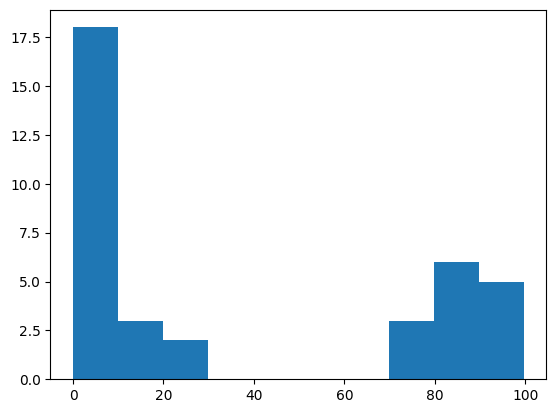

In [504]:
df3_missing = pd.DataFrame(df3.isna().sum()).reset_index(drop=False).rename(columns={'index':'col',0:'missing'})
df3_missing['missing_perc'] = df3_missing['missing'].divide(df3.shape[0])*100
plt.hist(df3_missing['missing_perc'])

In [505]:
df3_missing.columns

Index(['col', 'missing', 'missing_perc'], dtype='object')

In [506]:
df3_missing.shape

(37, 3)

In [507]:
df3_missing[df3_missing['missing_perc']>80].shape

(11, 3)

In [508]:
df3_missing[df3_missing['missing_perc']>80]['col'].to_list()

['ROE',
 'PEG',
 'EV_EBITDA',
 'Revenue_Growth',
 'NI_Growth',
 'CFO',
 'Ast_TO',
 'ROCE',
 'ROA',
 'Abn_Gain_Loss_Growth',
 'EBITDA_Growth']

In [509]:
missing_cols_drop = df3_missing[df3_missing['missing_perc']>80]['col'].to_list()
df3.drop(columns=missing_cols_drop,inplace=True)
df3.reset_index(drop=True,inplace=True)

C:\Users\35098\AppData\Local\Temp\ipykernel_17960\3096015063.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df3.drop(columns=missing_cols_drop,inplace=True)


In [510]:
df3.head()

,Ticker,Quarter,SMR,TMR,Std,Momentum,Beta,Alpha,EP,BP,...,Earnings_Growth_Flag,Zscore,FCF,ICR,200_MVA_Growth,50D_MVA_Growth,Volume_Growth,Abn_Gain_Loss_Flag,Mkt_Cap_Growth,Target
0,reliance,Q4FY05,5.388004,1.501305,1.278443,0.70,0.545504,0.004054,NaN,NaN,...,0,-0.416962,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0
1,reliance,Q1FY06,20.361842,49.591169,2.170369,5.49,0.997255,0.130998,NaN,NaN,...,0,-0.422182,NaN,NaN,NaN,NaN,NaN,0.0,0.176724,NaN
2,reliance,Q2FY06,45.305466,53.134531,2.668790,8.60,0.818094,0.023372,NaN,NaN,...,0,-0.316829,NaN,NaN,0.66768,9.082328,2.488304,0.0,0.235001,0.0
3,reliance,Q3FY06,38.398470,66.578947,2.300735,5.45,0.898060,0.061364,NaN,NaN,...,0,-0.270389,NaN,NaN,NaN,NaN,NaN,0.0,NaN,1.0
4,reliance,Q4FY06,98.539500,188.488746,12.334350,39.08,-0.778503,0.802280,NaN,NaN,...,0,0.283288,NaN,NaN,NaN,NaN,NaN,0.0,NaN,1.0


In [511]:
df3['Quarter'] = df3['Quarter'].apply(convert_qtr_to_date)
df3['Quarter'] = pd.to_datetime(df3['Quarter'],dayfirst=True)

C:\Users\35098\AppData\Local\Temp\ipykernel_17960\3470971761.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df3['Quarter'] = df3['Quarter'].apply(convert_qtr_to_date)
C:\Users\35098\AppData\Local\Temp\ipykernel_17960\3470971761.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df3['Quarter'] = pd.to_datetime(df3['Quarter'],dayfirst=True)


In [512]:
# df3['Quarter']

In [513]:
all_dates3 = df3['Quarter'].unique()
all_dates3 = pd.Series(all_dates3)
all_dates3.is_monotonic_increasing

True

In [514]:
all_dates3.sort_values(inplace=True)

In [515]:
all_dates3.reset_index(drop=True,inplace=True)

In [516]:
train_ind3 = int(len(all_dates3)*(1-test_size))
train_dates3 = all_dates3[:train_ind3]

In [517]:
df3['Set'] = np.where(df3['Quarter'].isin(train_dates3),"Train",'Test')

C:\Users\35098\AppData\Local\Temp\ipykernel_17960\3879384989.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df3['Set'] = np.where(df3['Quarter'].isin(train_dates3),"Train",'Test')


In [518]:
df3.columns

Index(['Ticker', 'Quarter', 'SMR', 'TMR', 'Std', 'Momentum', 'Beta', 'Alpha',
       'EP', 'BP', 'SP', 'DE', 'Dividend_Growth', 'Dividend_Flag', 'EPS',
       'Earnings_Growth', 'Earnings_Growth_Flag', 'Zscore', 'FCF', 'ICR',
       '200_MVA_Growth', '50D_MVA_Growth', 'Volume_Growth',
       'Abn_Gain_Loss_Flag', 'Mkt_Cap_Growth', 'Target', 'Set'],
      dtype='object')

In [519]:
df_train3 = df3[df3['Set']=='Train']
df_test3 = df3[df3['Set']=='Test']

In [520]:
iv_cols3 = list(df3.columns)
misc_cols = ['Ticker','Quarter','Target','Set']
for col in misc_cols:
    iv_cols3.remove(col)

In [521]:
iv_cols3

['SMR',
 'TMR',
 'Std',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'DE',
 'Dividend_Growth',
 'Dividend_Flag',
 'EPS',
 'Earnings_Growth',
 'Earnings_Growth_Flag',
 'Zscore',
 'FCF',
 'ICR',
 '200_MVA_Growth',
 '50D_MVA_Growth',
 'Volume_Growth',
 'Abn_Gain_Loss_Flag',
 'Mkt_Cap_Growth']

##### imputation

In [522]:
df_train3.columns

Index(['Ticker', 'Quarter', 'SMR', 'TMR', 'Std', 'Momentum', 'Beta', 'Alpha',
       'EP', 'BP', 'SP', 'DE', 'Dividend_Growth', 'Dividend_Flag', 'EPS',
       'Earnings_Growth', 'Earnings_Growth_Flag', 'Zscore', 'FCF', 'ICR',
       '200_MVA_Growth', '50D_MVA_Growth', 'Volume_Growth',
       'Abn_Gain_Loss_Flag', 'Mkt_Cap_Growth', 'Target', 'Set'],
      dtype='object')

In [523]:
iv_cols3

['SMR',
 'TMR',
 'Std',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'DE',
 'Dividend_Growth',
 'Dividend_Flag',
 'EPS',
 'Earnings_Growth',
 'Earnings_Growth_Flag',
 'Zscore',
 'FCF',
 'ICR',
 '200_MVA_Growth',
 '50D_MVA_Growth',
 'Volume_Growth',
 'Abn_Gain_Loss_Flag',
 'Mkt_Cap_Growth']

In [524]:
# df_train3.loc[:,'Quarter'] = pd.to_datetime(df_train3['Quarter'],dayfirst=True)
# df_test3.loc[:,'Quarter'] = pd.to_datetime(df_test3['Quarter'],dayfirst=True)

In [525]:
df_train3['Year'] = df_train3['Quarter'].dt.year
df_train3['Quarter_number'] = df_train3['Quarter'].dt.quarter

df_test3['Year'] = df_test3['Quarter'].dt.year
df_test3['Quarter_number'] = df_test3['Quarter'].dt.quarter

C:\Users\35098\AppData\Local\Temp\ipykernel_17960\3770018300.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train3['Year'] = df_train3['Quarter'].dt.year
C:\Users\35098\AppData\Local\Temp\ipykernel_17960\3770018300.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train3['Quarter_number'] = df_train3['Quarter'].dt.quarter
C:\Users\35098\AppData\Local\Temp\ipykernel_17960\3770018300.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[r

In [526]:
df_train3 = df_train3.set_index(['Quarter'])
df_test3 = df_test3.set_index(['Quarter'])

In [527]:
for col in iv_cols3:
    df_train3.loc[:,col] = df_train3[col].astype(float)
    df_test3.loc[:,col] = df_test3[col].astype(float)
    df_train3.loc[:,col] = df_train3.groupby('Ticker')[col].transform(lambda group: group.interpolate(method='time',limit_direction='forward'))
    df_test3.loc[:,col] = df_test3.groupby('Ticker')[col].transform(lambda group: group.interpolate(method='time',limit_direction='forward'))

In [528]:
df_train3.isna().sum()

Ticker                      0
SMR                       580
TMR                      1103
Std                        35
Momentum                  327
Beta                       40
Alpha                      56
EP                       5251
BP                       4331
SP                       4896
DE                       4953
Dividend_Growth          4930
Dividend_Flag               0
EPS                      4608
Earnings_Growth             0
Earnings_Growth_Flag        0
Zscore                    313
FCF                      6706
ICR                      8055
200_MVA_Growth           2503
50D_MVA_Growth           1887
Volume_Growth            2018
Abn_Gain_Loss_Flag          0
Mkt_Cap_Growth           1148
Target                  23034
Set                         0
Year                        0
Quarter_number              0
dtype: int64

In [529]:
df_train3.reset_index(inplace=True)
df_test3.reset_index(inplace=True)

In [530]:
for col in iv_cols3:
    df_train3.loc[:,col] = df_train3.groupby('Quarter')[col].transform(lambda group: group.fillna(group.median()))
    df_test3.loc[:,col] = df_test3.groupby('Quarter')[col].transform(lambda group: group.fillna(group.median()))

d:\Quant Fund\qf_33\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1241: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
d:\Quant Fund\qf_33\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1241: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
d:\Quant Fund\qf_33\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1241: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
d:\Quant Fund\qf_33\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1241: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
d:\Quant Fund\qf_33\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1241: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
d:\Quant Fund\qf_33\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1241: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepd

In [531]:
# df_test.isna().sum()

In [532]:
df_train3.fillna({'Target':0},inplace=True)
df_test3.fillna({'Target':0},inplace=True)

In [533]:
df_train3['Ticker'].nunique()

741

In [534]:
df_train3['Year'] = df_train3['Quarter'].dt.year
df_train3['Quarter_number'] = df_train3['Quarter'].dt.quarter

df_test3['Year'] = df_test3['Quarter'].dt.year
df_test3['Quarter_number'] = df_test3['Quarter'].dt.quarter

##### Multi-collinearity check

In [535]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [536]:
iv_cols3

['SMR',
 'TMR',
 'Std',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'DE',
 'Dividend_Growth',
 'Dividend_Flag',
 'EPS',
 'Earnings_Growth',
 'Earnings_Growth_Flag',
 'Zscore',
 'FCF',
 'ICR',
 '200_MVA_Growth',
 '50D_MVA_Growth',
 'Volume_Growth',
 'Abn_Gain_Loss_Flag',
 'Mkt_Cap_Growth']

In [537]:
iv_cols3 = iv_cols3 + ['Year','Quarter_number']

In [538]:
vif_data3 = pd.DataFrame()
vif_data3["feature"] = iv_cols3

In [539]:
df_train3[iv_cols3].isin([np.inf,-np.inf]).sum()

SMR                      0
TMR                      0
Std                      0
Momentum                 0
Beta                     0
Alpha                    0
EP                       0
BP                       4
SP                       0
DE                       0
Dividend_Growth          0
Dividend_Flag            0
EPS                      0
Earnings_Growth          0
Earnings_Growth_Flag     0
Zscore                   0
FCF                      0
ICR                      0
200_MVA_Growth          47
50D_MVA_Growth          70
Volume_Growth            0
Abn_Gain_Loss_Flag       0
Mkt_Cap_Growth           0
Year                     0
Quarter_number           0
dtype: int64

In [540]:
df_train3.replace([np.inf,-np.inf],0,inplace=True)

In [541]:
for col in iv_cols3:
    df_train3.loc[:,col] = df_train3[col].astype(float)

In [542]:
df_train3.isna().sum()

Quarter                   0
Ticker                    0
SMR                       0
TMR                       0
Std                       0
Momentum                  0
Beta                      0
Alpha                     0
EP                        0
BP                        0
SP                        0
DE                        0
Dividend_Growth         485
Dividend_Flag             0
EPS                       0
Earnings_Growth           0
Earnings_Growth_Flag      0
Zscore                    0
FCF                       0
ICR                       0
200_MVA_Growth          970
50D_MVA_Growth          970
Volume_Growth           970
Abn_Gain_Loss_Flag        0
Mkt_Cap_Growth          485
Target                    0
Set                       0
Year                      0
Quarter_number            0
dtype: int64

In [543]:
df_train3.fillna(0,inplace=True)

In [544]:
vif_data3["VIF"] = [variance_inflation_factor(df_train3[iv_cols3].values, i) for i in range(len(iv_cols3))]

In [545]:
vif_data3.head()

,feature,VIF
0,SMR,2.089478
1,TMR,1.720776
2,Std,1.592450
3,Momentum,1.196505
4,Beta,3.048518


In [546]:
vif_cols3 = vif_data3[vif_data3['VIF']<5]['feature'].to_list()
vif_cols3

['SMR',
 'TMR',
 'Std',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'DE',
 'Dividend_Growth',
 'Dividend_Flag',
 'EPS',
 'Earnings_Growth',
 'Earnings_Growth_Flag',
 'Zscore',
 'FCF',
 'ICR',
 '200_MVA_Growth',
 '50D_MVA_Growth',
 'Volume_Growth',
 'Abn_Gain_Loss_Flag',
 'Mkt_Cap_Growth']

In [547]:
import seaborn as sns

In [548]:
# ax = sns.heatmap(df_fin2[vif_cols].corr(), annot=True)
df_train3[vif_cols3+['Target']].corr().style.background_gradient(cmap='coolwarm')

,SMR,TMR,Std,Momentum,Beta,Alpha,EP,BP,SP,DE,Dividend_Growth,Dividend_Flag,EPS,Earnings_Growth,Earnings_Growth_Flag,Zscore,FCF,ICR,200_MVA_Growth,50D_MVA_Growth,Volume_Growth,Abn_Gain_Loss_Flag,Mkt_Cap_Growth,Target
SMR,1.000000,0.599682,0.021623,0.087449,0.003821,0.549489,-0.052107,-0.050729,-0.013613,-0.005707,-0.029992,-0.050301,0.008371,-0.004069,0.004151,0.004351,0.021900,-0.006115,-0.000356,0.006931,0.010875,-0.005251,0.312792,0.059332
TMR,0.599682,1.000000,0.023920,0.063051,0.030461,0.373340,-0.055444,-0.059555,-0.015843,-0.006490,-0.017808,-0.042996,0.008779,-0.003228,0.002719,0.010249,0.025080,-0.005756,0.002256,0.007774,-0.004842,-0.002603,0.189449,0.058160
Std,0.021623,0.023920,1.000000,0.382707,-0.014473,0.031952,-0.040374,-0.034922,-0.009526,-0.010187,0.007940,0.043697,0.272759,0.000371,0.002584,0.438859,0.010455,0.006343,0.001015,0.000847,0.000373,-0.011572,0.009215,-0.025769
Momentum,0.087449,0.063051,0.382707,1.000000,-0.011891,0.122620,-0.020969,-0.017494,-0.004494,-0.003540,-0.010050,0.014705,0.111329,-0.000606,0.006133,0.135698,0.003760,-0.001501,0.000678,-0.000748,-0.000967,-0.010440,0.067811,-0.008505
Beta,0.003821,0.030461,-0.014473,-0.011891,1.000000,0.055312,0.012647,0.026980,0.017790,0.020995,-0.002682,-0.058771,-0.017072,0.003165,-0.003229,-0.074096,-0.008126,-0.014424,-0.015835,0.007159,0.007564,0.009854,0.004212,-0.007715
Alpha,0.549489,0.373340,0.031952,0.122620,0.055312,1.000000,-0.032387,-0.034323,-0.009470,-0.001431,-0.038491,-0.025710,0.011673,-0.000400,0.000289,0.007636,0.014148,-0.003845,-0.001264,0.004478,-0.003916,-0.000648,0.425717,0.049202
EP,-0.052107,-0.055444,-0.040374,-0.020969,0.012647,-0.032387,1.000000,0.172506,0.065757,0.356811,0.020862,-0.037510,0.000716,0.003377,-0.005148,-0.078363,-0.047253,-0.006197,0.000043,-0.000016,-0.002594,0.011695,-0.021127,0.017302
BP,-0.050729,-0.059555,-0.034922,-0.017494,0.026980,-0.034323,0.172506,1.000000,0.380197,-0.005979,0.004450,-0.055888,-0.016472,-0.000123,-0.003834,-0.075157,-0.186893,-0.009444,-0.000912,-0.000563,-0.004742,0.008916,-0.019564,0.013630
SP,-0.013613,-0.015843,-0.009526,-0.004494,0.017790,-0.009470,0.065757,0.380197,1.000000,0.011499,-0.001323,-0.015835,-0.016578,-0.000487,-0.002082,-0.023082,-0.439975,-0.002057,0.000578,-0.000701,0.000383,0.000466,-0.003386,-0.002996
DE,-0.005707,-0.006490,-0.010187,-0.003540,0.020995,-0.001431,0.356811,-0.005979,0.011499,1.000000,-0.000804,-0.067106,-0.011617,-0.000554,-0.001562,-0.027399,-0.007689,-0.002784,0.000571,0.000226,0.000431,0.002852,-0.002355,0.000341


In [549]:
for col in ['SMR']:
# for col in ['EP']:
# for col in ['EP']:
    vif_cols3.remove(col)

In [550]:
# ax = sns.heatmap(df_fin2[vif_cols].corr(), annot=True)
df_train3[vif_cols3+['Target']].corr().style.background_gradient(cmap='coolwarm')

,TMR,Std,Momentum,Beta,Alpha,EP,BP,SP,DE,Dividend_Growth,Dividend_Flag,EPS,Earnings_Growth,Earnings_Growth_Flag,Zscore,FCF,ICR,200_MVA_Growth,50D_MVA_Growth,Volume_Growth,Abn_Gain_Loss_Flag,Mkt_Cap_Growth,Target
TMR,1.000000,0.023920,0.063051,0.030461,0.373340,-0.055444,-0.059555,-0.015843,-0.006490,-0.017808,-0.042996,0.008779,-0.003228,0.002719,0.010249,0.025080,-0.005756,0.002256,0.007774,-0.004842,-0.002603,0.189449,0.058160
Std,0.023920,1.000000,0.382707,-0.014473,0.031952,-0.040374,-0.034922,-0.009526,-0.010187,0.007940,0.043697,0.272759,0.000371,0.002584,0.438859,0.010455,0.006343,0.001015,0.000847,0.000373,-0.011572,0.009215,-0.025769
Momentum,0.063051,0.382707,1.000000,-0.011891,0.122620,-0.020969,-0.017494,-0.004494,-0.003540,-0.010050,0.014705,0.111329,-0.000606,0.006133,0.135698,0.003760,-0.001501,0.000678,-0.000748,-0.000967,-0.010440,0.067811,-0.008505
Beta,0.030461,-0.014473,-0.011891,1.000000,0.055312,0.012647,0.026980,0.017790,0.020995,-0.002682,-0.058771,-0.017072,0.003165,-0.003229,-0.074096,-0.008126,-0.014424,-0.015835,0.007159,0.007564,0.009854,0.004212,-0.007715
Alpha,0.373340,0.031952,0.122620,0.055312,1.000000,-0.032387,-0.034323,-0.009470,-0.001431,-0.038491,-0.025710,0.011673,-0.000400,0.000289,0.007636,0.014148,-0.003845,-0.001264,0.004478,-0.003916,-0.000648,0.425717,0.049202
EP,-0.055444,-0.040374,-0.020969,0.012647,-0.032387,1.000000,0.172506,0.065757,0.356811,0.020862,-0.037510,0.000716,0.003377,-0.005148,-0.078363,-0.047253,-0.006197,0.000043,-0.000016,-0.002594,0.011695,-0.021127,0.017302
BP,-0.059555,-0.034922,-0.017494,0.026980,-0.034323,0.172506,1.000000,0.380197,-0.005979,0.004450,-0.055888,-0.016472,-0.000123,-0.003834,-0.075157,-0.186893,-0.009444,-0.000912,-0.000563,-0.004742,0.008916,-0.019564,0.013630
SP,-0.015843,-0.009526,-0.004494,0.017790,-0.009470,0.065757,0.380197,1.000000,0.011499,-0.001323,-0.015835,-0.016578,-0.000487,-0.002082,-0.023082,-0.439975,-0.002057,0.000578,-0.000701,0.000383,0.000466,-0.003386,-0.002996
DE,-0.006490,-0.010187,-0.003540,0.020995,-0.001431,0.356811,-0.005979,0.011499,1.000000,-0.000804,-0.067106,-0.011617,-0.000554,-0.001562,-0.027399,-0.007689,-0.002784,0.000571,0.000226,0.000431,0.002852,-0.002355,0.000341
Dividend_Growth,-0.017808,0.007940,-0.010050,-0.002682,-0.038491,0.020862,0.004450,-0.001323,-0.000804,1.000000,0.011256,0.005906,0.000267,-0.002637,-0.002364,0.000650,0.013991,0.002313,-0.000052,-0.000119,0.001005,-0.025322,-0.001558


In [551]:
sign_cols3 = ['Ticker','Quarter']+vif_cols3+['Target']

In [552]:
sign_cols3

['Ticker',
 'Quarter',
 'TMR',
 'Std',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'DE',
 'Dividend_Growth',
 'Dividend_Flag',
 'EPS',
 'Earnings_Growth',
 'Earnings_Growth_Flag',
 'Zscore',
 'FCF',
 'ICR',
 '200_MVA_Growth',
 '50D_MVA_Growth',
 'Volume_Growth',
 'Abn_Gain_Loss_Flag',
 'Mkt_Cap_Growth',
 'Target']

In [553]:
test_size

0.3

In [554]:
from datetime import datetime
# print()
date1 = f"{datetime.today().date()}"
date1 = date1.replace("-","_")
print(date1)

2025_07_03


In [555]:
# df_train3[sign_cols3].to_excel(rf"D:\FY25-26\Quant Fund\Fund3\data\train_data_after_multicollinearity_correlation_{int(test_size*100)}_test_size_time_based_split_{date1}.xlsx",index=False)
# df_test3[sign_cols3].to_excel(rf"D:\FY25-26\Quant Fund\Fund3\data\test_data_after_multicollinearity_correlation_{int(test_size*100)}_test_size_time_based_split_{date1}.xlsx",index=False)

In [ ]:
df_train.to_excel(rf"D:\FY25-26\Quant Fund\Fund3\data\train_data_after_multicollinearity_correlation_{int(test_size*100)}_test_size_time_based_split_{date1}.xlsx",index=False)
df_test.to_excel(rf"D:\FY25-26\Quant Fund\Fund3\data\test_data_after_multicollinearity_correlation_{int(test_size*100)}_test_size_time_based_split_{date1}.xlsx",index=False)